In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

In [2]:
cols = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d", "word_freq_our",
    "word_freq_over", "word_freq_remove", "word_freq_internet", "word_freq_order", "word_freq_mail",
    "word_freq_receive", "word_freq_will", "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money", "word_freq_hp",
    "word_freq_hpl", "word_freq_george", "word_freq_650", "word_freq_lab", "word_freq_labs",
    "word_freq_telnet", "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference",
    "char_freq_;", "char_freq_(", "char_freq_[", "char_freq_!", "char_freq_$", "char_freq_#",
    "capital_run_length_average", "capital_run_length_longest", "capital_run_length_total",
    "spam"
]

df = pd.read_csv("spambase.data", names=cols)
df.head()


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


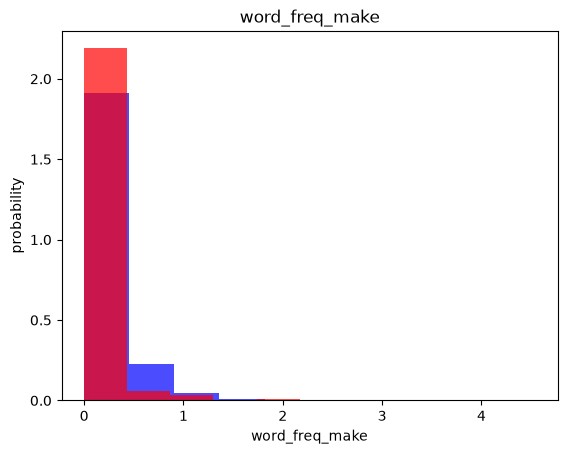

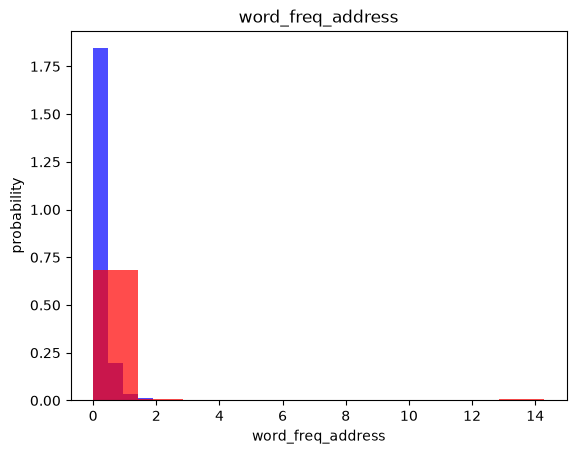

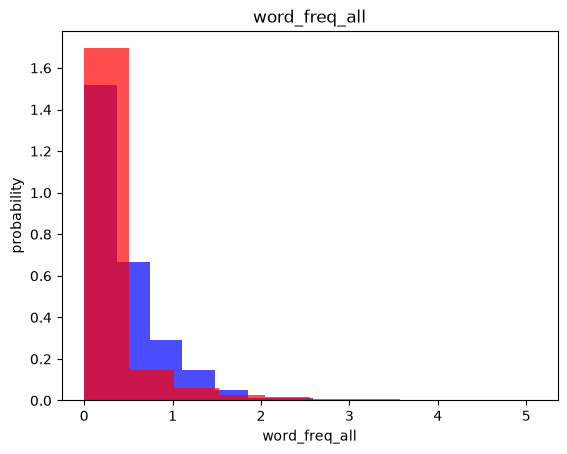

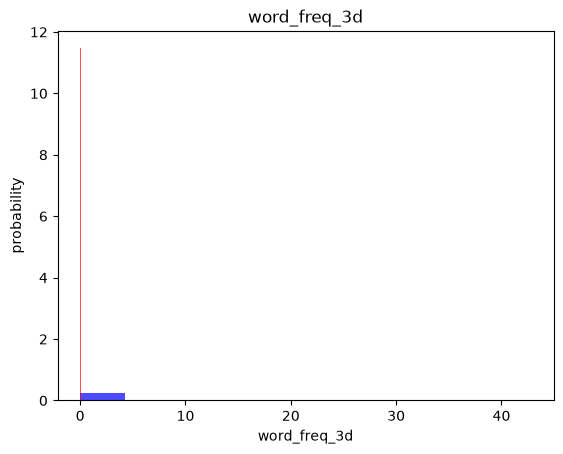

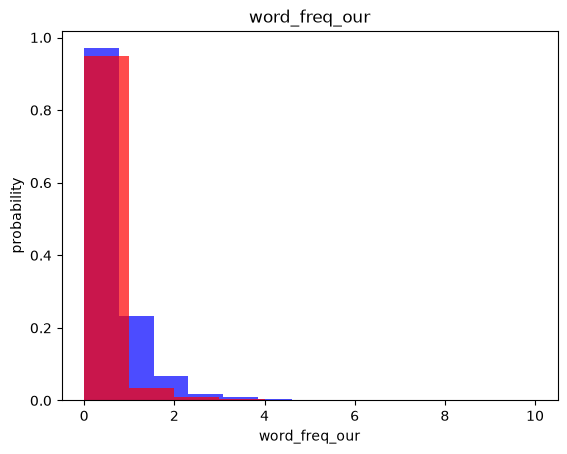

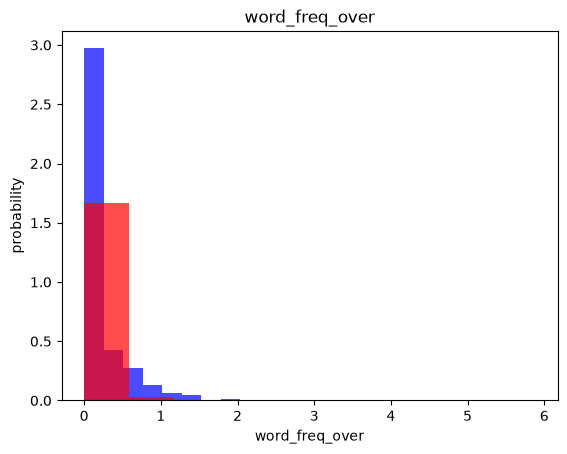

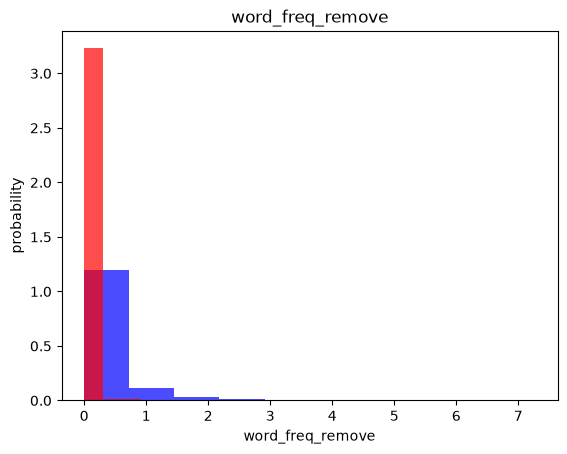

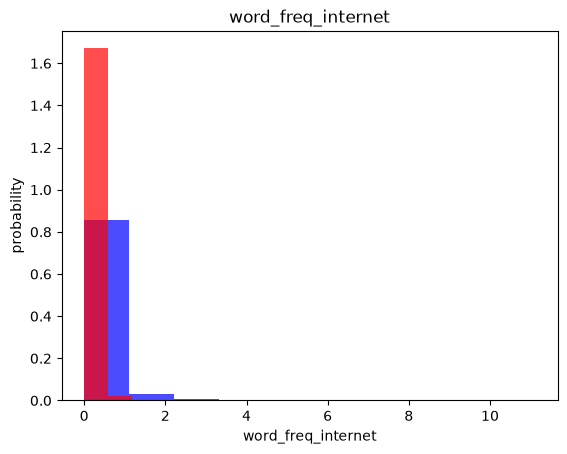

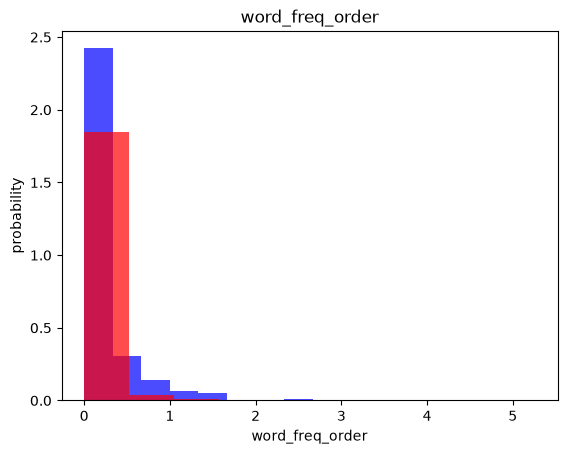

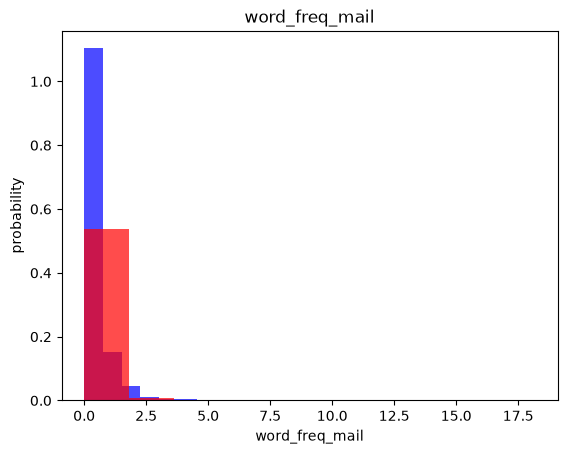

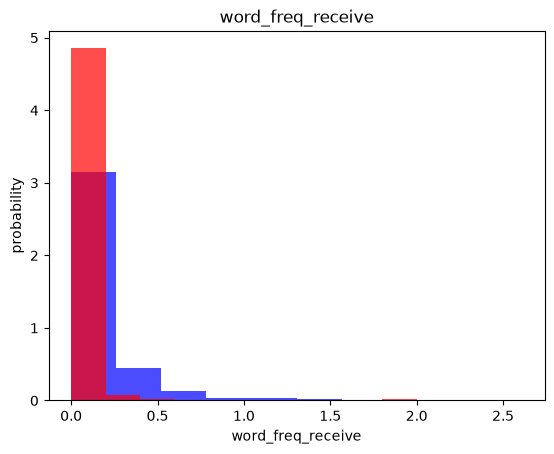

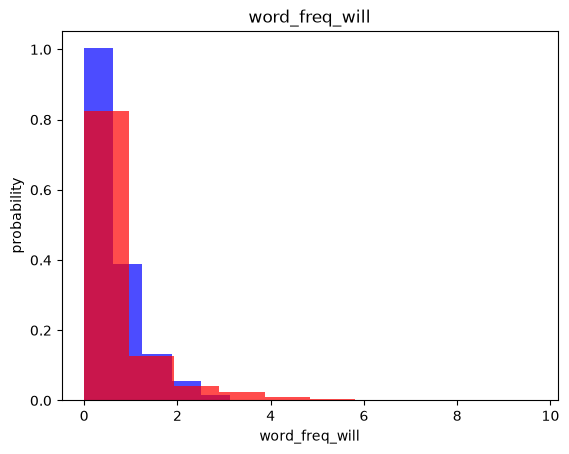

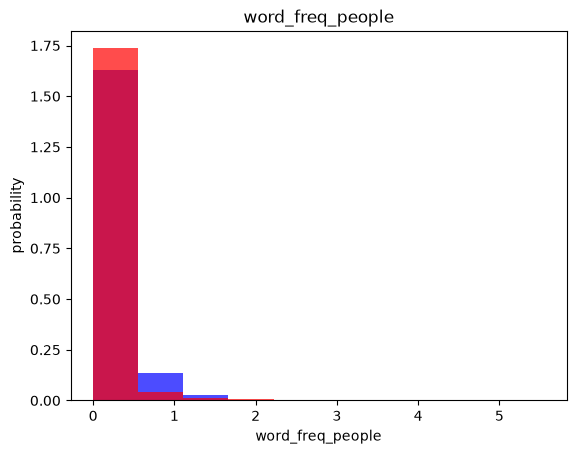

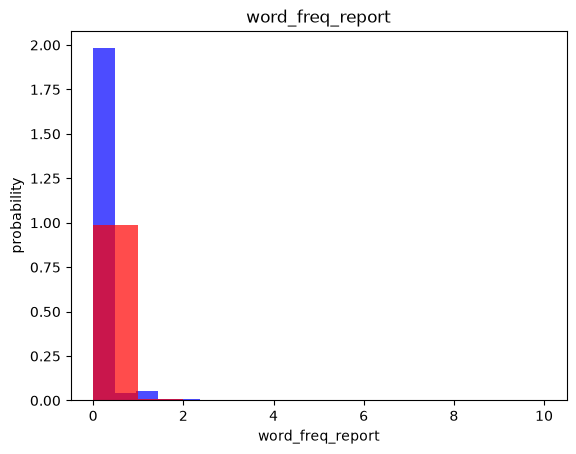

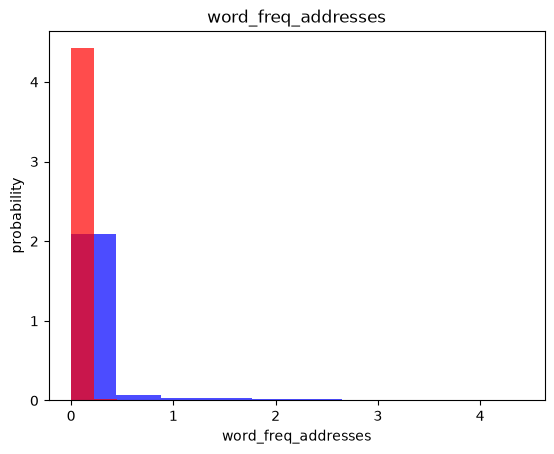

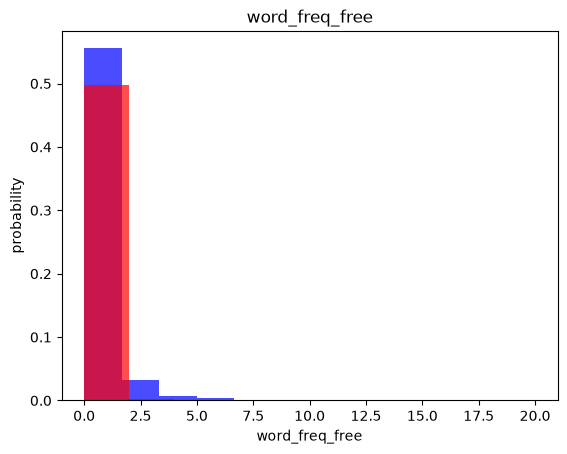

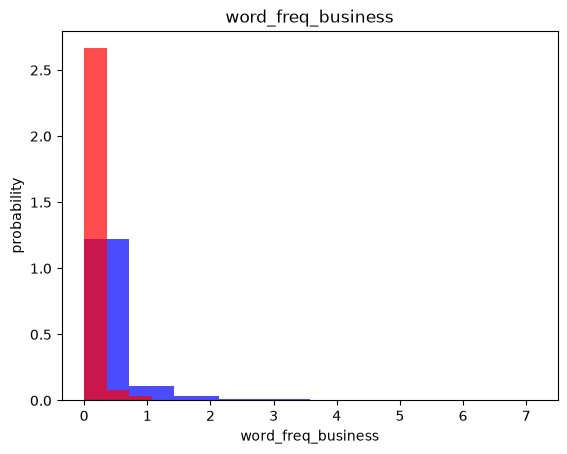

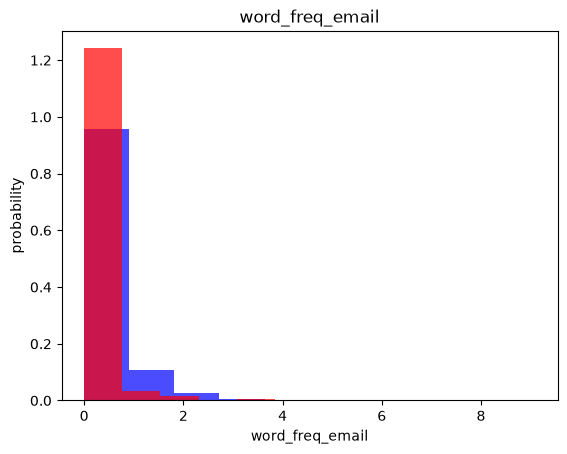

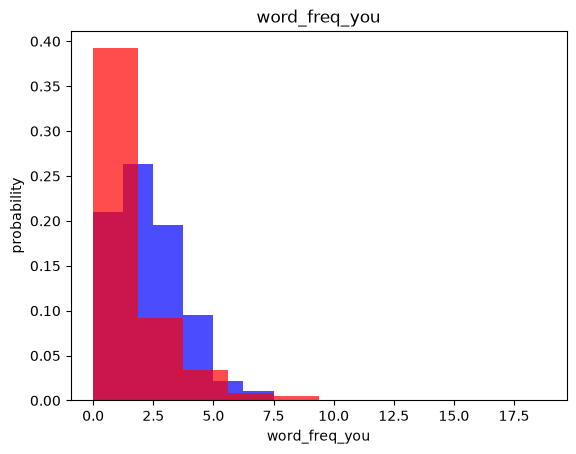

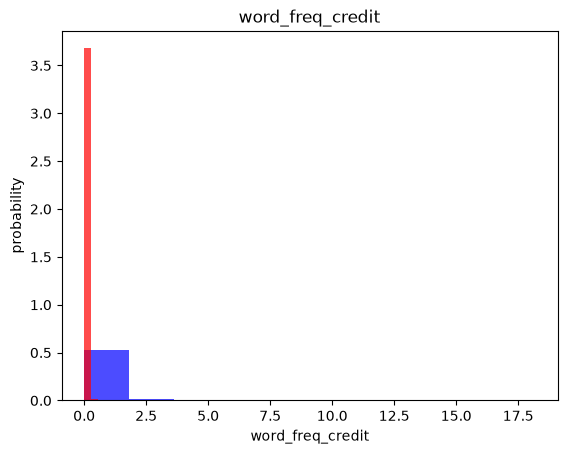

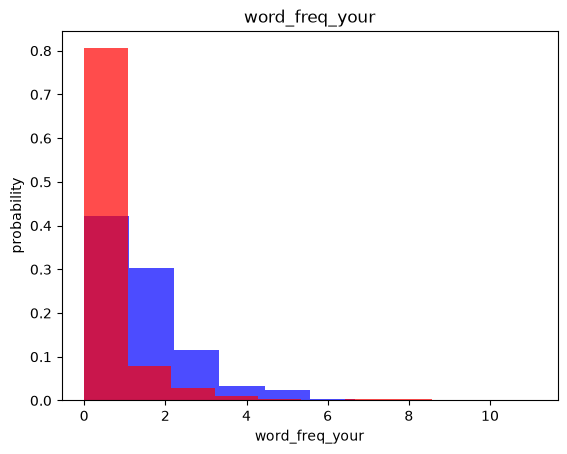

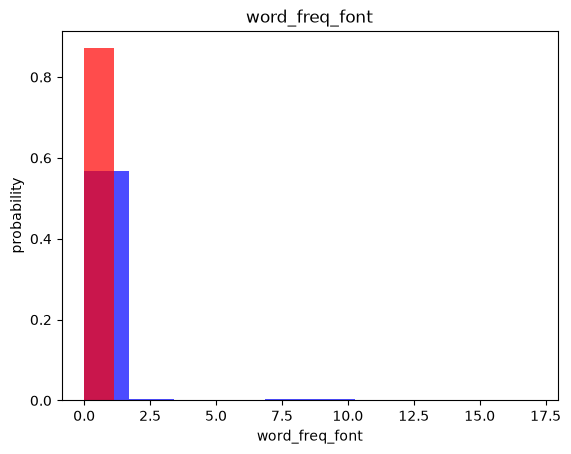

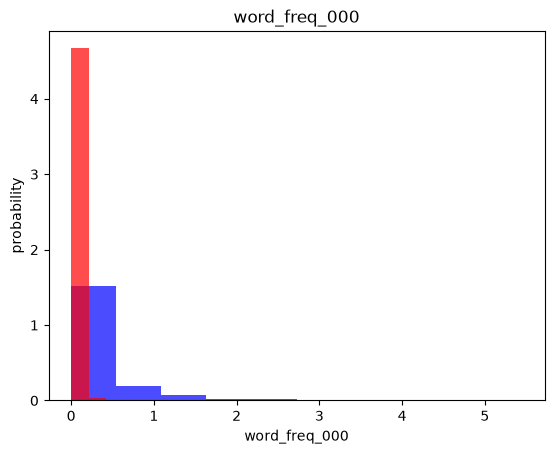

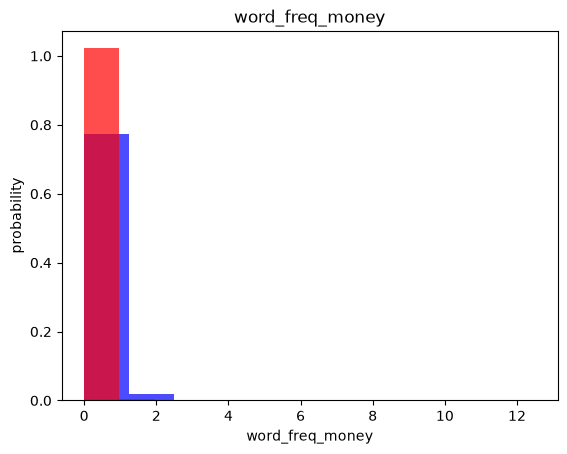

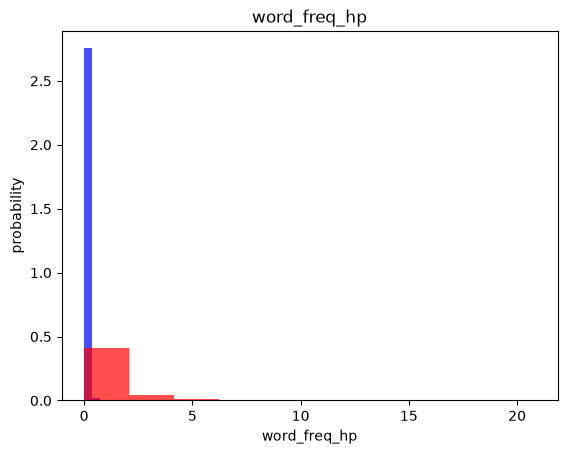

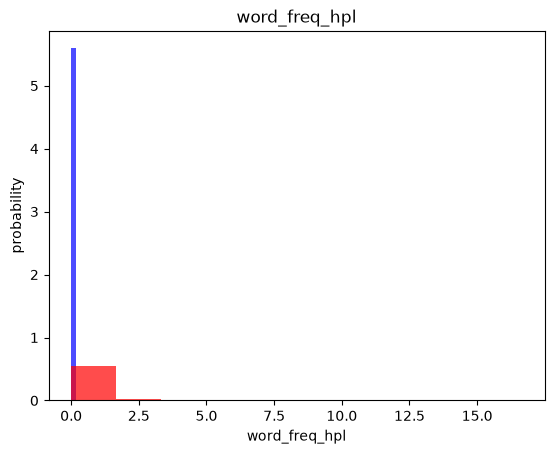

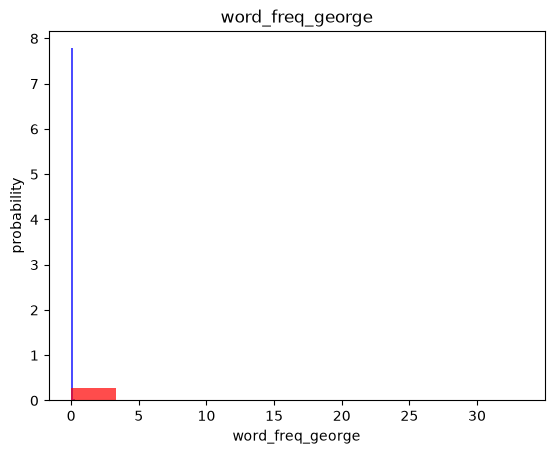

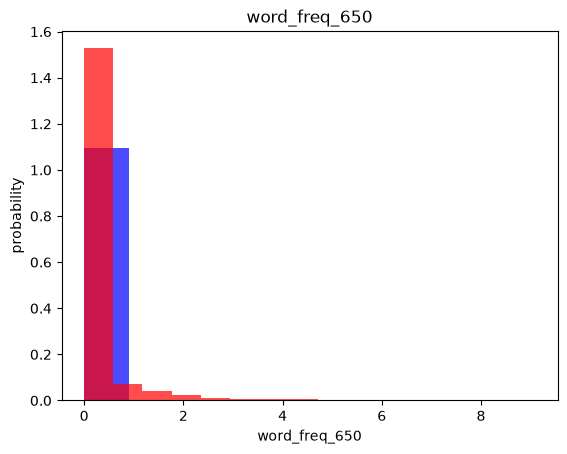

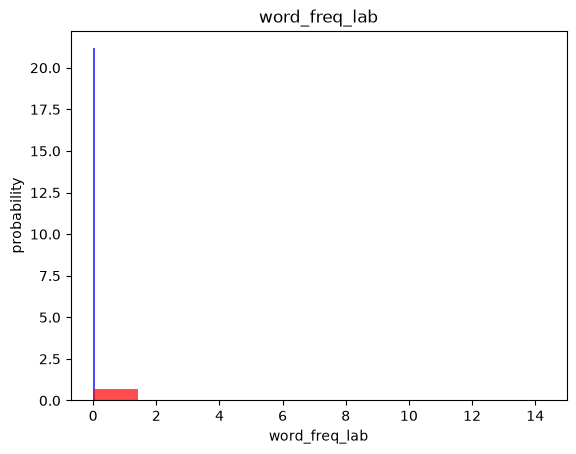

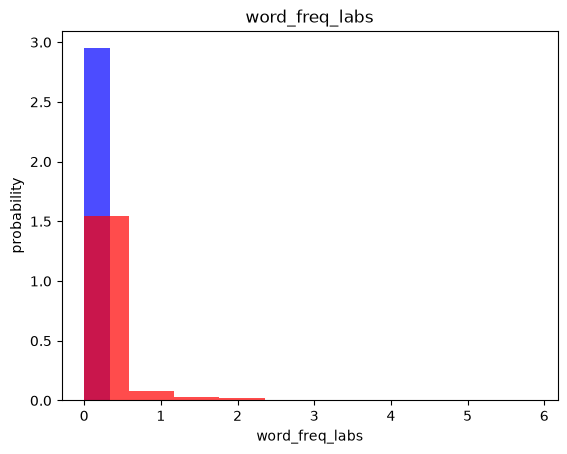

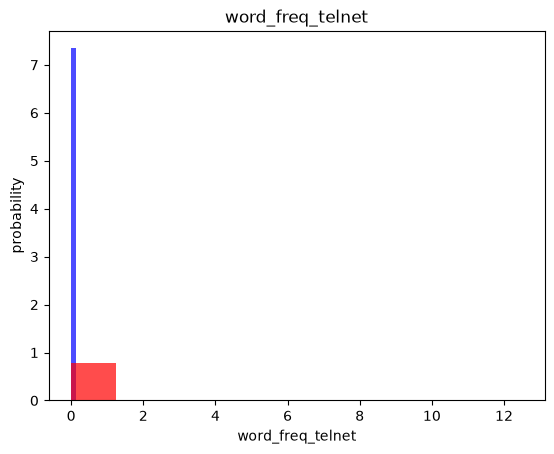

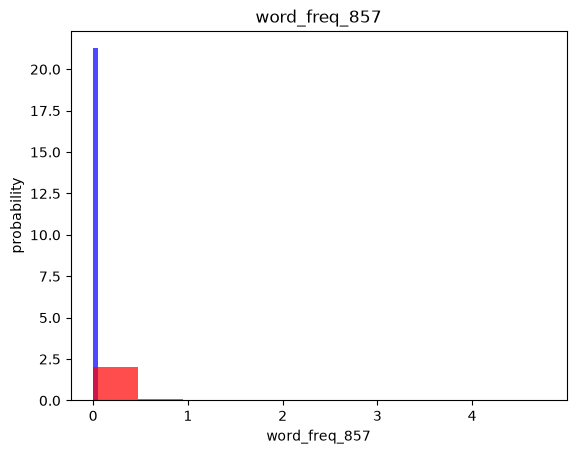

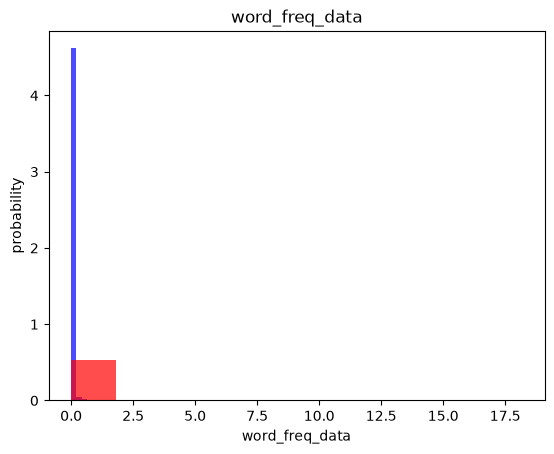

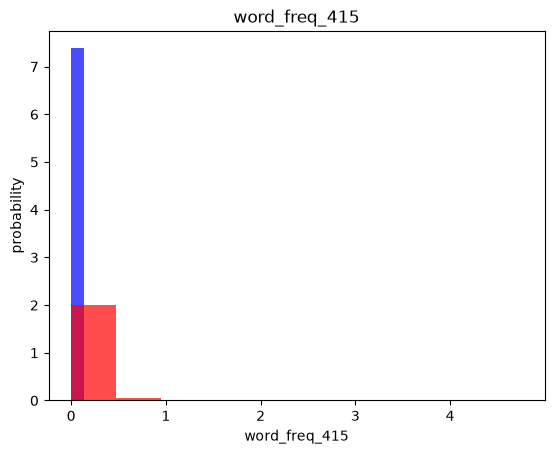

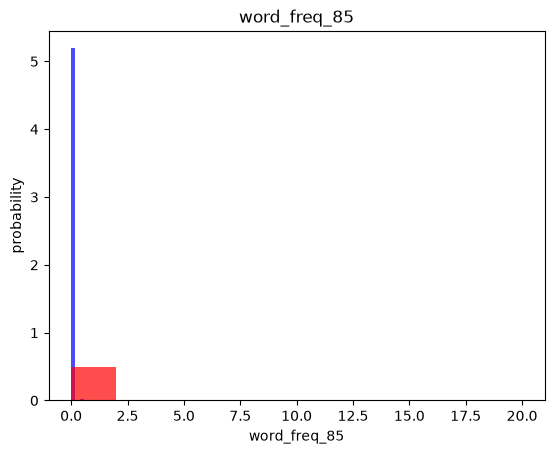

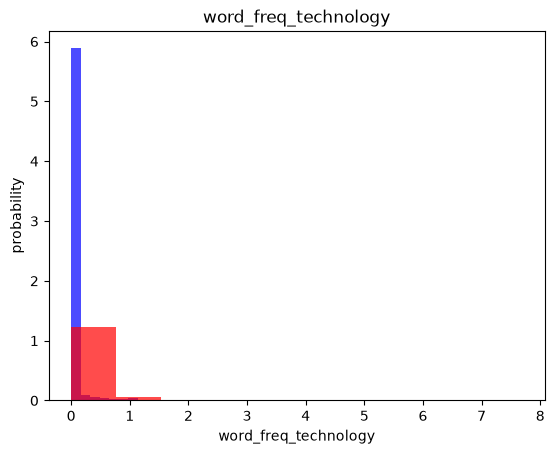

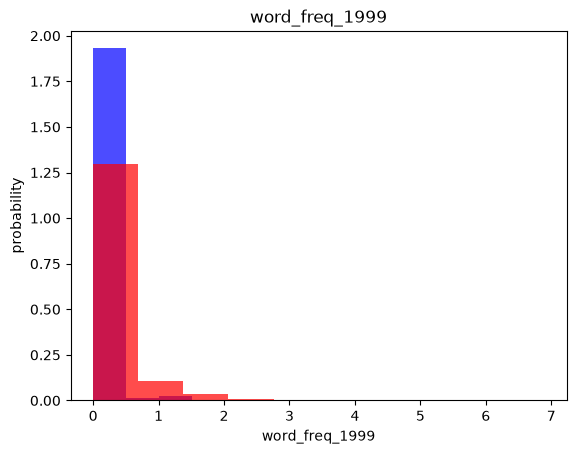

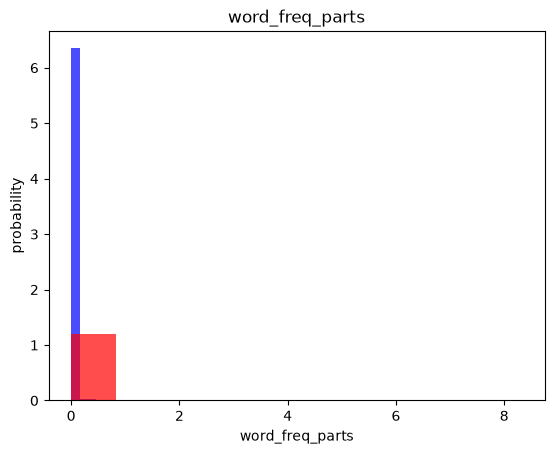

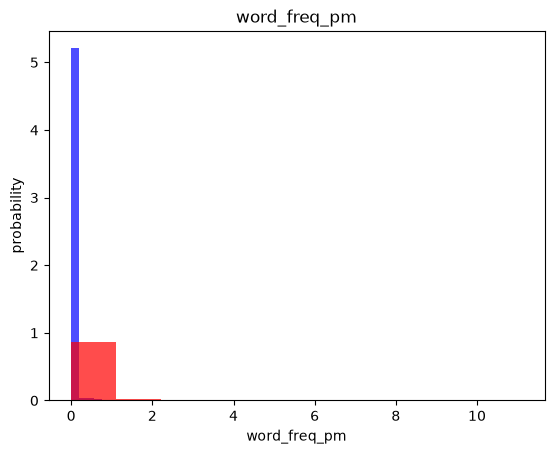

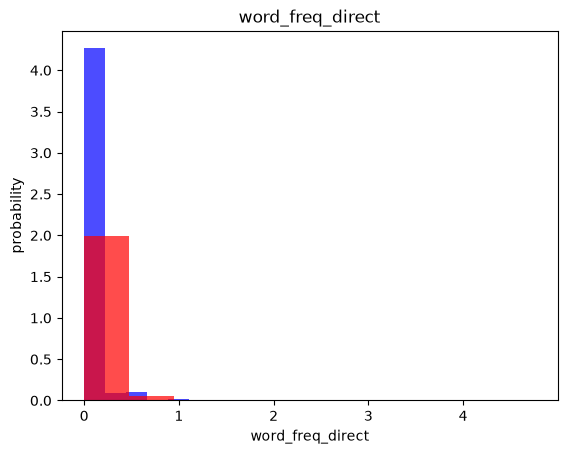

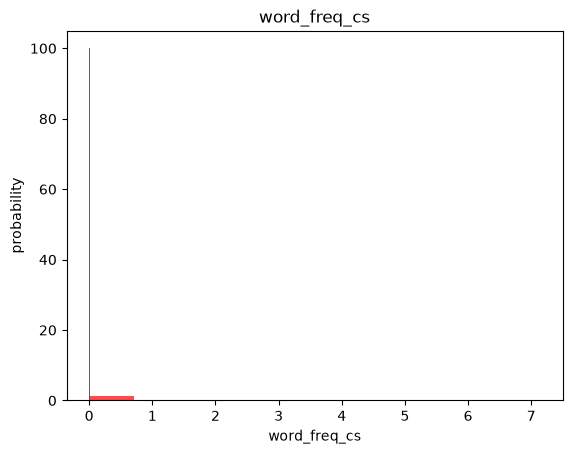

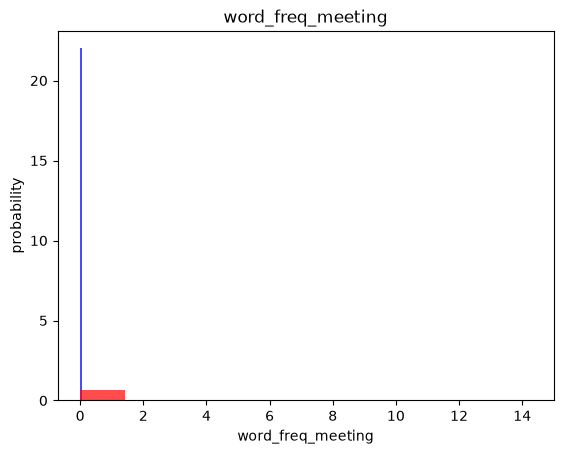

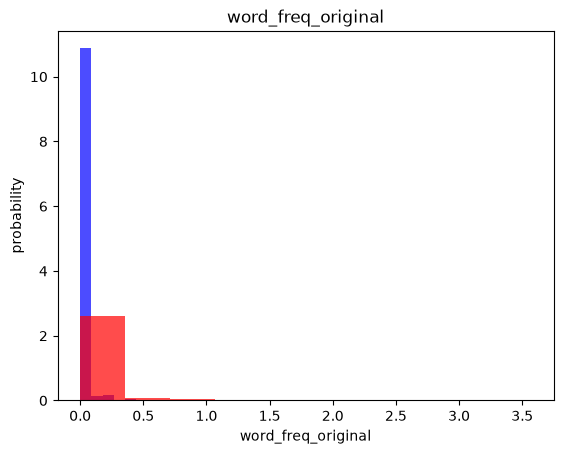

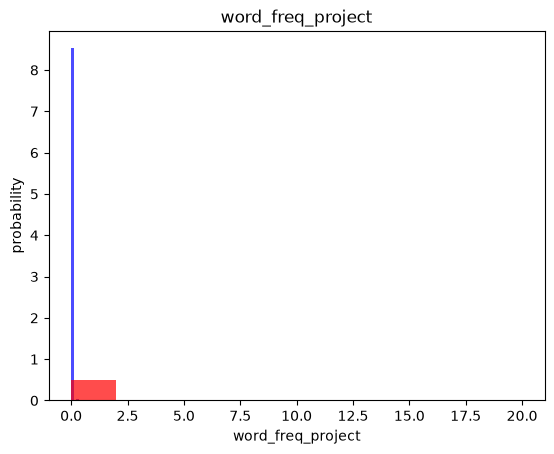

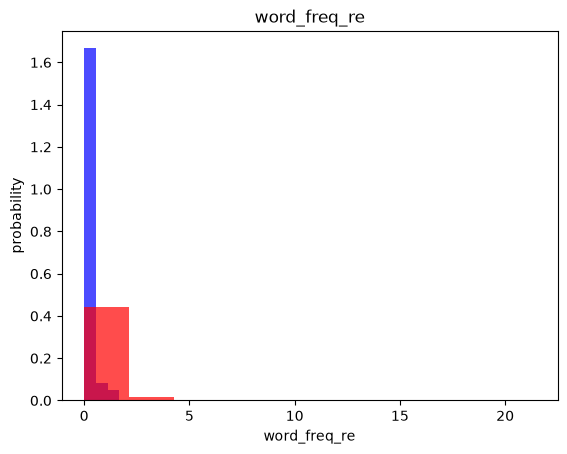

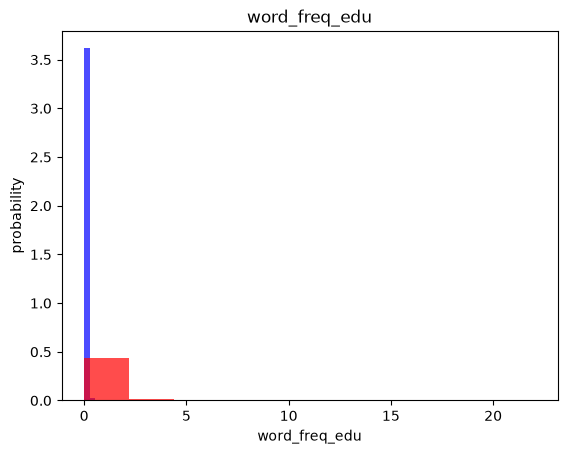

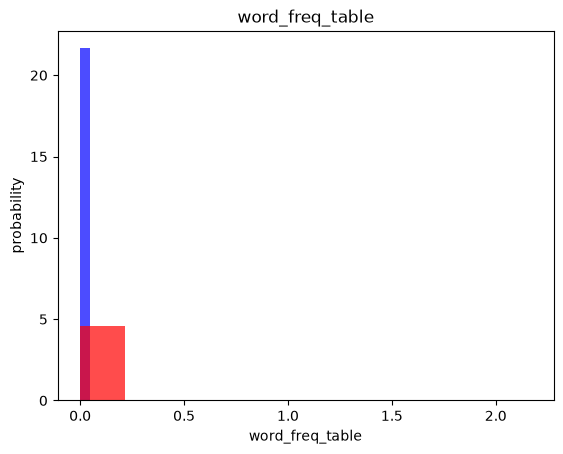

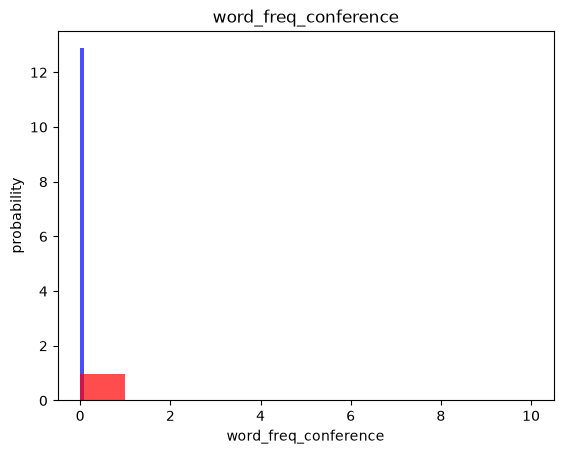

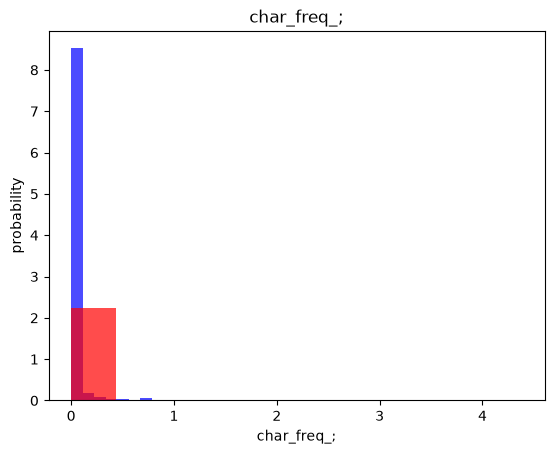

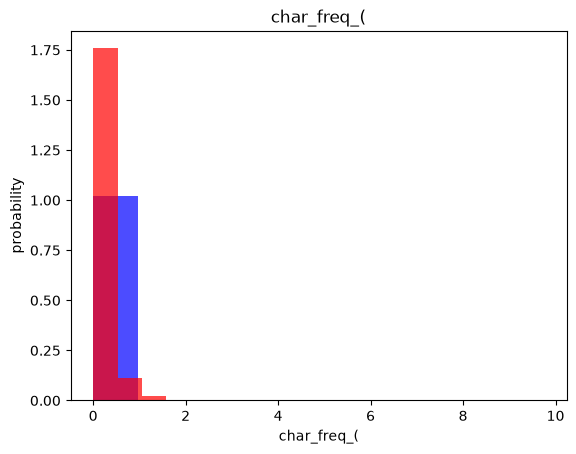

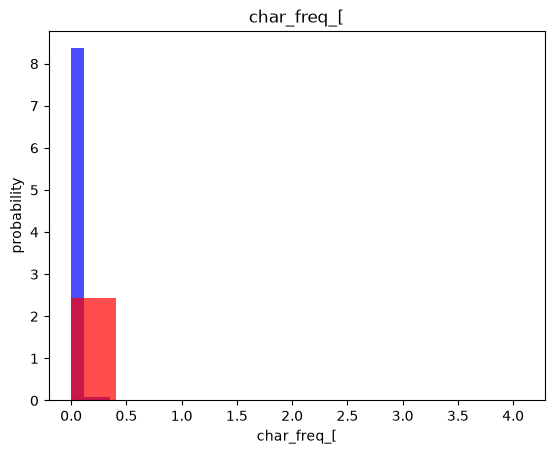

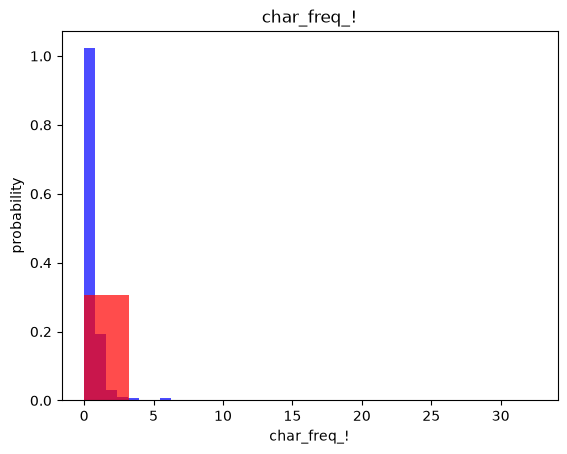

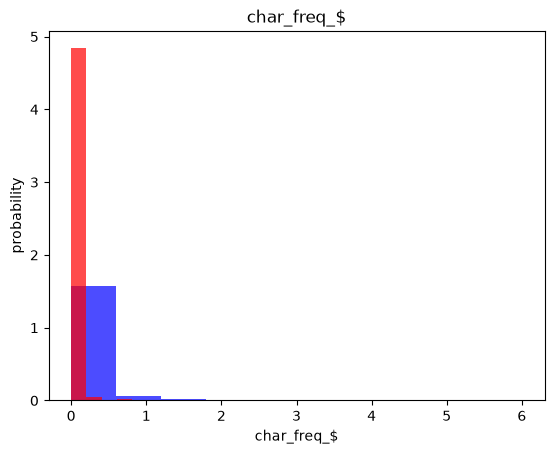

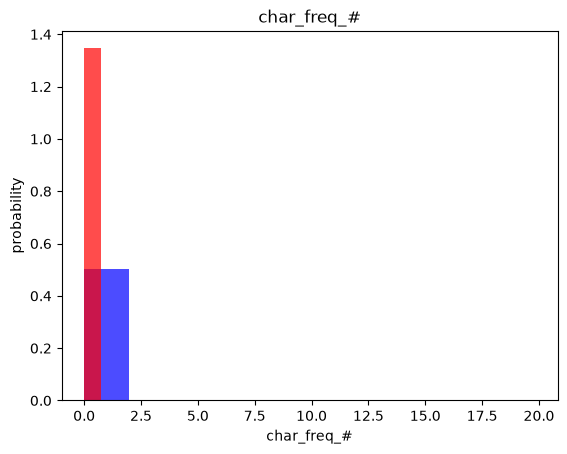

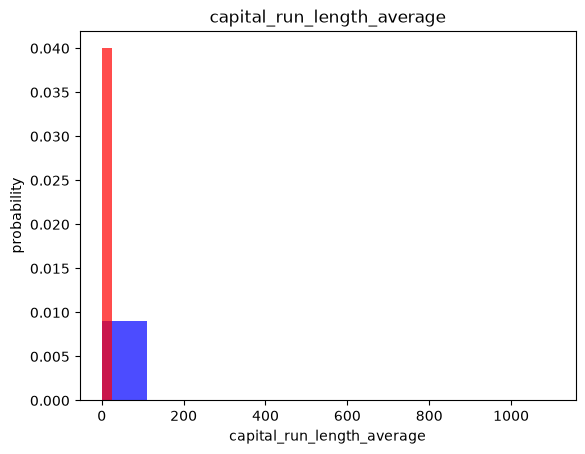

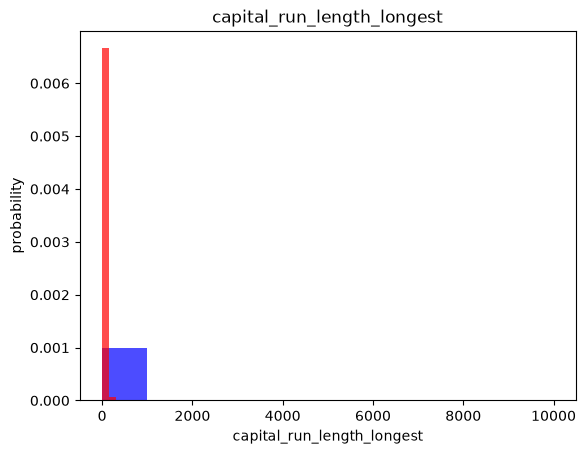

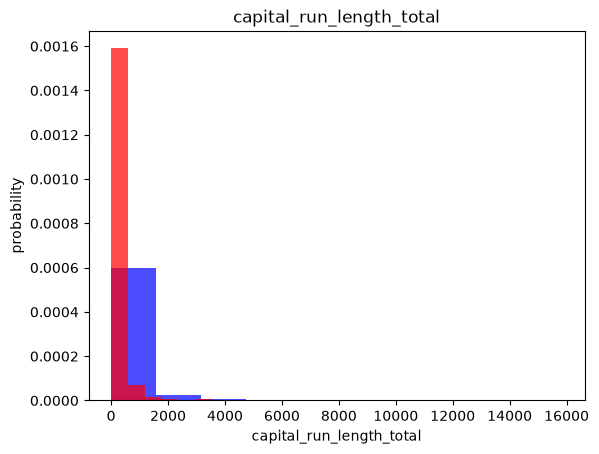

In [3]:
for label in cols[:-1]:
  plt.hist(df[df["spam"] == 1][label], color = 'blue', label = 'spam', alpha = 0.7, density = True)
  plt.hist(df[df["spam"] == 0][label], color = 'red', label = 'non_spam', alpha = 0.7, density = True)
  # density being true just nromalises distribution
  plt.title(label)
  plt.ylabel("probability")
  plt.xlabel(label)
  plt.show()

In [4]:
train, valid, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

In [5]:
def scale_dataset(dataframe, oversample = False):
  x = dataframe[dataframe.columns[:-1]].values
  y = dataframe[dataframe.columns[-1]].values

  scaler =  StandardScaler()
  X =  scaler.fit_transform(x) #this fits all x values into standard scaler and transforms the data
#horizontally stacking data;

  if oversample == True:

    ros = RandomOverSampler()
    X, y = ros.fit_resample(X,y) # this is telling the code to take the less class
    #and keep sampling from there to oncrease the dataset so the two match


    data = np.hstack((X, np.reshape(y, (-1, 1))))
    # here, np.reshape(y, (-1, 1)) means for array y,
    #make it 1 column, and figure out how many rows (as many as needed)
    return data, X, y
  else:
    X, y = X, y
    data = dataframe

    return data, X, y


# print(len(train[train["class"]== 1])) # this will be length of gamma
# print(len(train[train["class"]== 0])) # this will be length of hadrons
#this produced values
#7409
#4003
###that code doesnt work now because we added to our previous code as well
# we need to oversample our training dataset to match each other, this is done by increasing number of
#hadron datasets we have using a library

#Therefore::
train, X_train, y_train = scale_dataset(train, oversample=True)
valid, X_valid, y_valid = scale_dataset(valid, oversample=False)
test, X_test, y_test = scale_dataset(test, oversample=False)

#now once we train they should be the same value:

print(len(X_train)) # this will be length of gamma
print(len(y_train)) # this will be length of hadrons



AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train,y_train)

KNeighborsClassifier()

In [ ]:
y_pred = knn_model.predict(X_test)

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.93       564
           1       0.88      0.89      0.88       357

    accuracy                           0.91       921
   macro avg       0.90      0.91      0.91       921
weighted avg       0.91      0.91      0.91       921



In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train,y_train)



GaussianNB()

In [ ]:
y_pred = nb_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.61      1.00      0.76       564
           1       1.00      0.01      0.01       357

    accuracy                           0.61       921
   macro avg       0.81      0.50      0.39       921
weighted avg       0.76      0.61      0.47       921



In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lg_model = LogisticRegression()
lg_model = lg_model.fit(X_train, y_train)

In [ ]:
y_pred = lg_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       564
           1       0.90      0.92      0.91       357

    accuracy                           0.93       921
   macro avg       0.92      0.93      0.93       921
weighted avg       0.93      0.93      0.93       921



In [ ]:
from sklearn.svm import SVC

In [ ]:
svm_model = SVC() #hover over to see details
svm_model = svm_model.fit(X_train, y_train)

In [ ]:
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94       564
           1       0.92      0.89      0.90       357

    accuracy                           0.93       921
   macro avg       0.93      0.92      0.92       921
weighted avg       0.93      0.93      0.93       921



In [ ]:
#Neural Networks***

In [ ]:
import tensorflow as tf

In [ ]:
nn_model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation = 'relu', input_shape=(10,)),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(1, activation = 'sigmoid')

])

nn_model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss = 'binary_crossentropy',
                    metrics = ['accuracy']

                    )

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
def plot_loss(history):
    plt.plot(history.history['loss'], label='loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.xlabel('Epoch')
    plt.ylabel('Binary crossentropy')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_accuracy(history):
    plt.plot(history.history['accuracy'], label='accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()
    #these codes above are obtained by TensorFlow library-- can be obtained by any TensorFlow tutorial



In [ ]:
nn_model = tf.keras.Sequential([
    tf.keras.layers.Dense(57, activation = 'relu', input_shape=(57,)),
    tf.keras.layers.Dense(57, activation = 'relu'),
    tf.keras.layers.Dense(1, activation = 'sigmoid')

])
#had to change input shape to the number of features here

nn_model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss = 'binary_crossentropy',
                    metrics = ['accuracy']

                    )

In [ ]:
history = nn_model.fit(
    X_train, y_train, epochs=100, batch_size=57, validation_split=0.2, verbose=0 #validation split fractions the data to use validation data- a little like our validation dataset but from the training data
)
#LOOONGGGGG CODE -DO NOT RUN IF NOT NEEDED TAKES 5 MINS

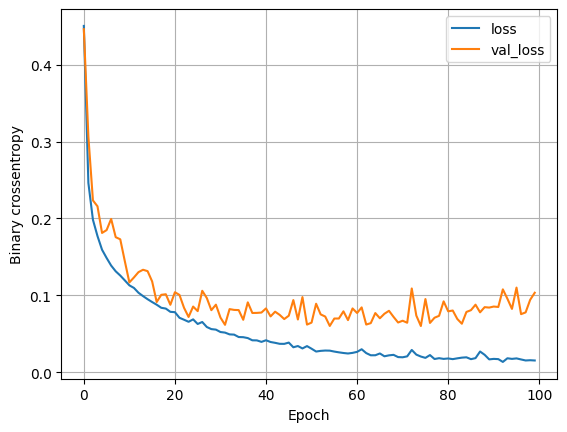

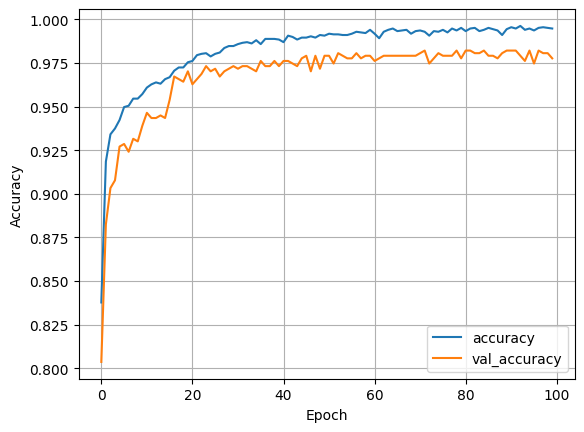

In [ ]:
plot_loss(history)
plot_accuracy(history)

In [ ]:
def plot_history(history):
  fig, (ax1, ax2) = plt.subplots(1,2) # this is sayingn i want one row and two columns iin that row for my plots
  ax1.plot(history.history['loss'], label='loss')
  ax1.plot(history.history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.legend()
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  plt.show()


    #these codes above are obtained by TensorFlow library-- can be obtained by any TensorFlow tutorial


In [ ]:
###
def train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs):


  nn_model = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(57,)),
      tf.keras.layers.Dense(num_nodes, activation = 'relu', input_shape=(10,)),
      #changing the nodes to 64 will give us 64 in the first layer
      #A lot of ML involves determining what to set these parameters- look9ing at what happens when they are changed
      tf.keras.layers.Dropout(dropout_prob),
      #dropout says randomly choose certain nodes and dont train them in a certian iteration- this prevents overfitting
      tf.keras.layers.Dense(num_nodes, activation = 'relu'),
      #
      tf.keras.layers.Dropout(dropout_prob),
      #
      tf.keras.layers.Dense(1, activation = 'sigmoid')

  ])

  nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss = 'binary_crossentropy',
                      metrics = ['accuracy']

                      )
  history = nn_model.fit(
    X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=0 #validation split fractions the data to use validation data-
    #a little like our validation dataset but from the training data
  )
  return nn_model, history



In [ ]:
#next will be building a hyperparameter to tune the neural network built


16 nodes, dropout 0, lr0.01, batch_size16


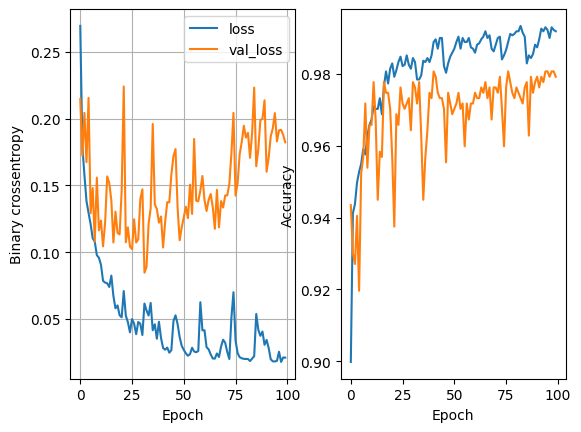

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9117 - loss: 1.3299  
16 nodes, dropout 0, lr0.01, batch_size32


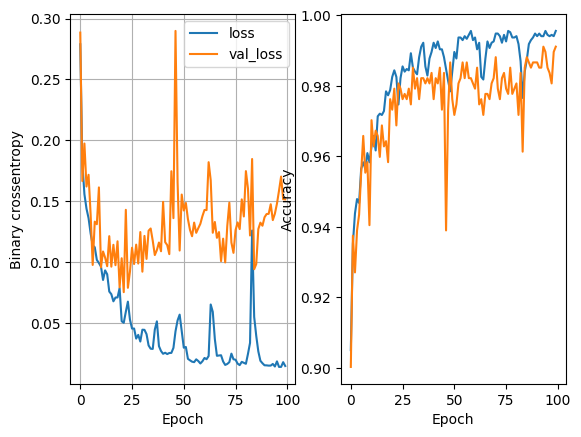

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9171 - loss: 1.1338  
16 nodes, dropout 0, lr0.01, batch_size64


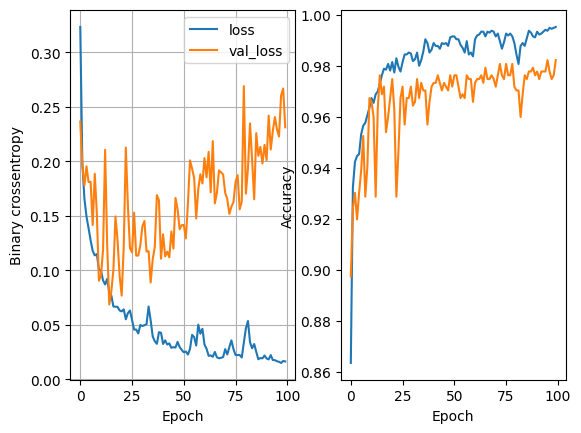

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9422 - loss: 0.7648 
16 nodes, dropout 0, lr0.005, batch_size16


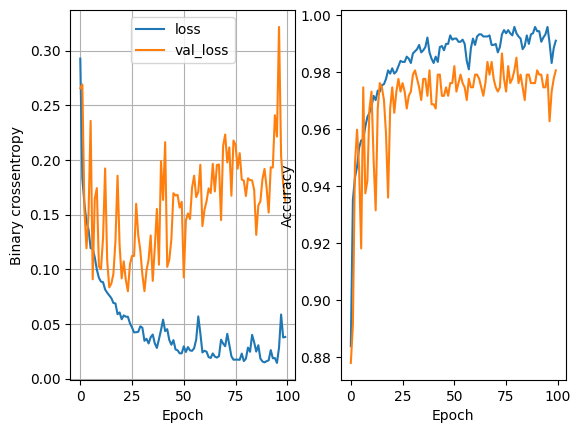

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9197 - loss: 0.9797  
16 nodes, dropout 0, lr0.005, batch_size32


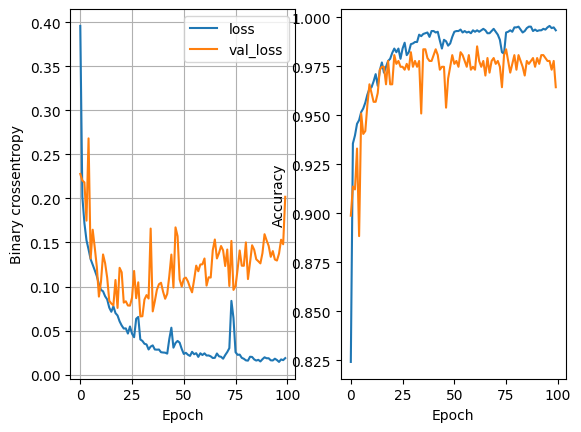

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9237 - loss: 0.8264  
16 nodes, dropout 0, lr0.005, batch_size64


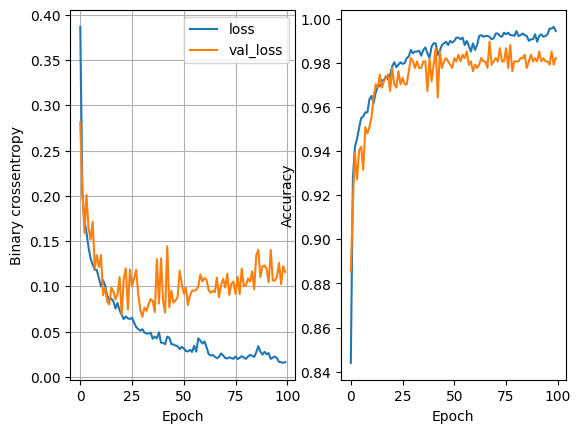

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9171 - loss: 0.8511
16 nodes, dropout 0, lr0.001, batch_size16


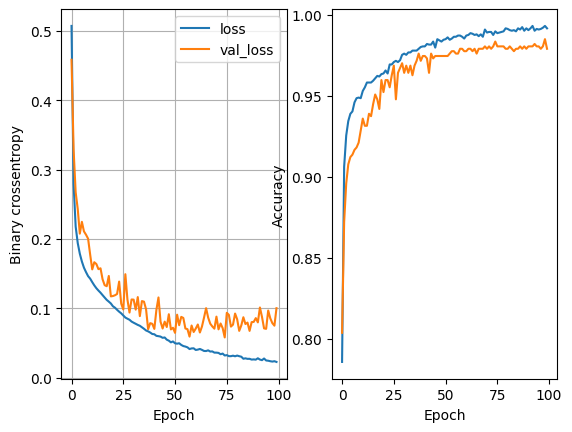

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9192 - loss: 0.5728
16 nodes, dropout 0, lr0.001, batch_size32


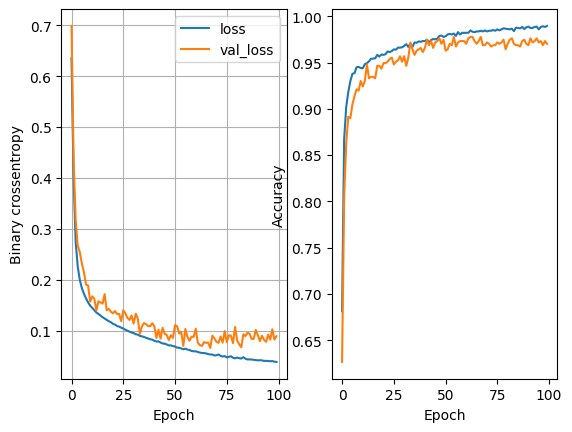

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9056 - loss: 0.4505
16 nodes, dropout 0, lr0.001, batch_size64


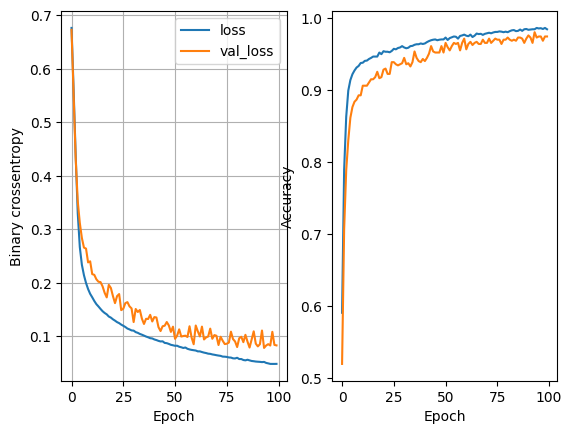

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9291 - loss: 0.2832 
16 nodes, dropout 0.2, lr0.01, batch_size16


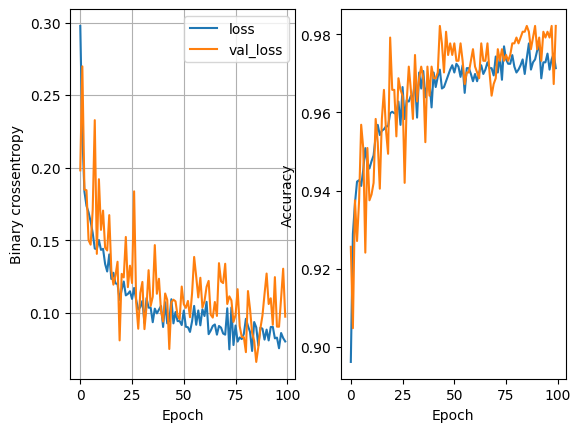

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9219 - loss: 0.7781
16 nodes, dropout 0.2, lr0.01, batch_size32


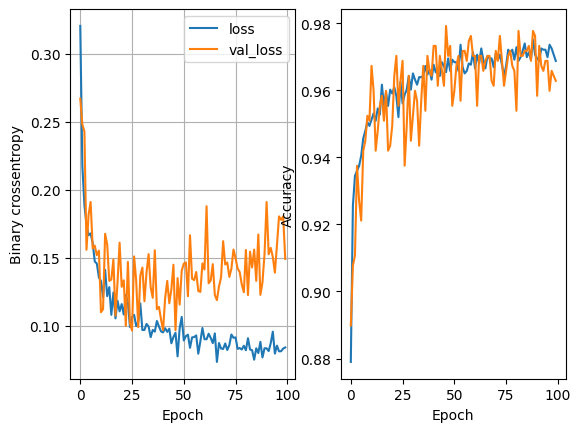

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9237 - loss: 0.4788
16 nodes, dropout 0.2, lr0.01, batch_size64


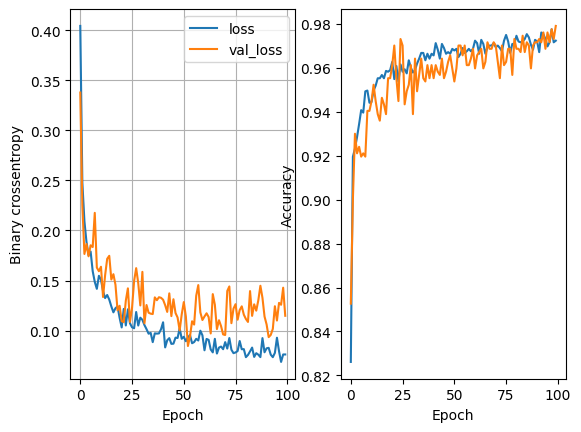

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9242 - loss: 0.5629 
16 nodes, dropout 0.2, lr0.005, batch_size16


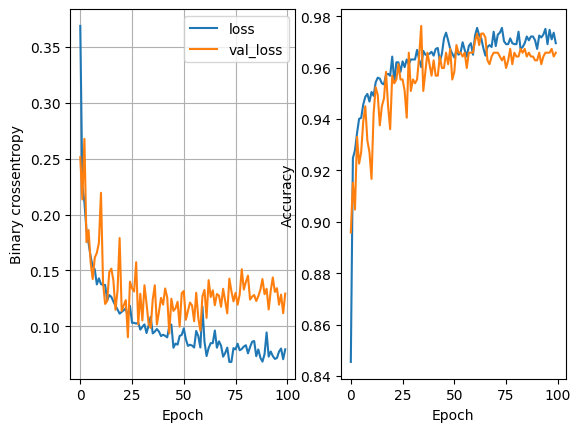

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9267 - loss: 0.4977
16 nodes, dropout 0.2, lr0.005, batch_size32


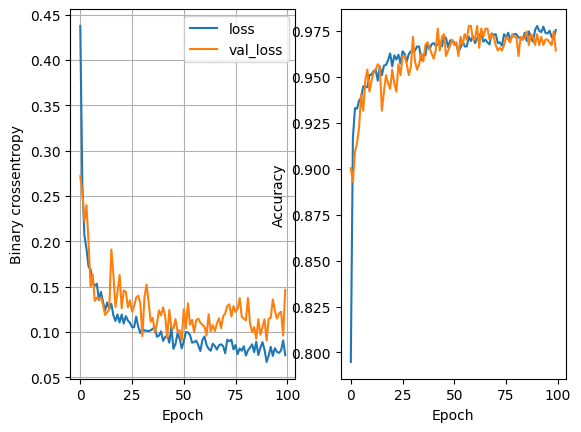

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9275 - loss: 0.4643
16 nodes, dropout 0.2, lr0.005, batch_size64


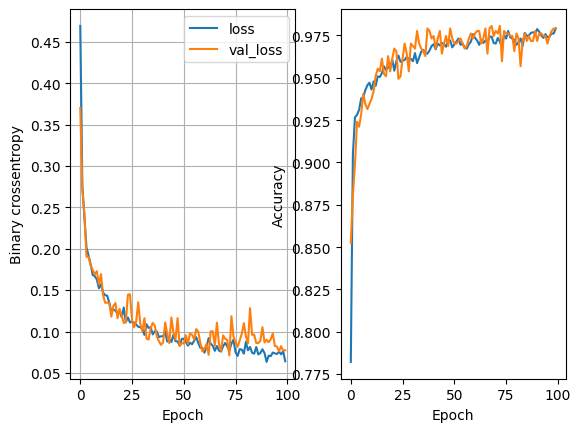

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9281 - loss: 0.3934
16 nodes, dropout 0.2, lr0.001, batch_size16


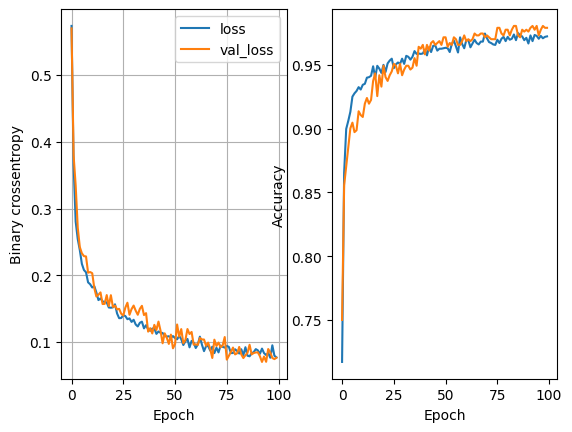

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9314 - loss: 0.3104
16 nodes, dropout 0.2, lr0.001, batch_size32


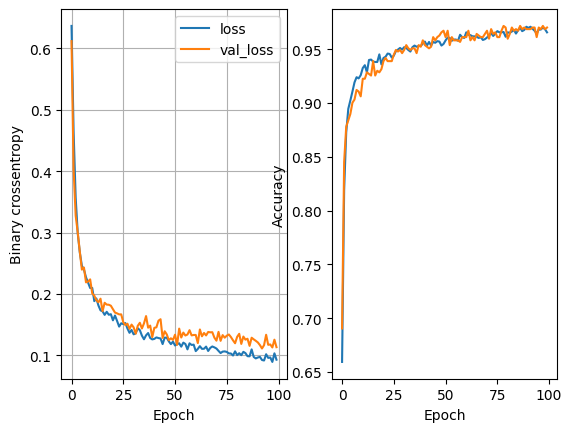

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9232 - loss: 0.2608  
16 nodes, dropout 0.2, lr0.001, batch_size64


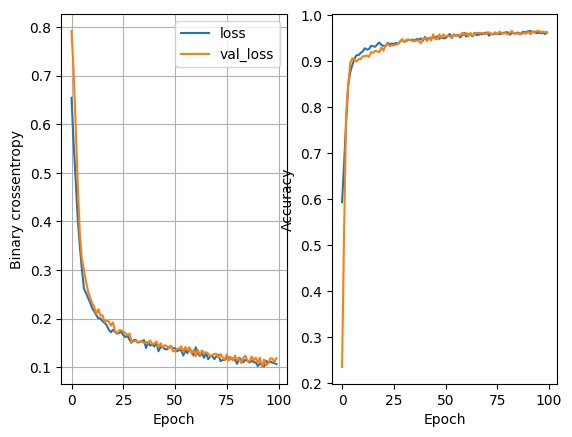

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9290 - loss: 0.2158
16 nodes, dropout 0.4, lr0.01, batch_size16


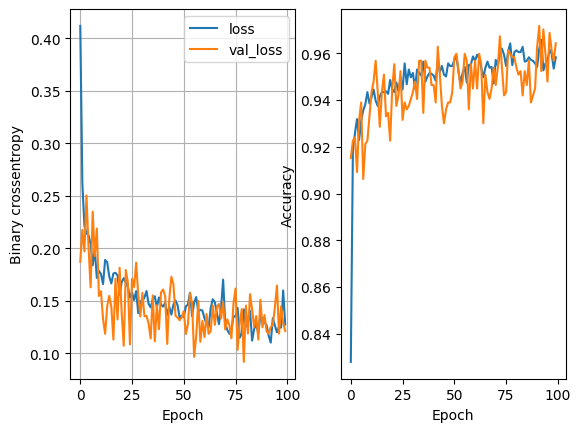

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9301 - loss: 0.4863
16 nodes, dropout 0.4, lr0.01, batch_size32


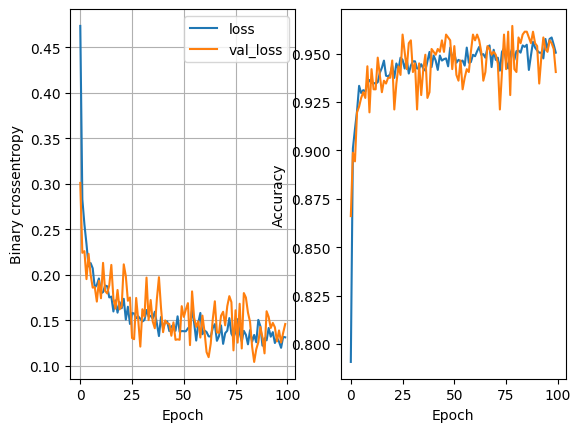

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9225 - loss: 0.3894
16 nodes, dropout 0.4, lr0.01, batch_size64


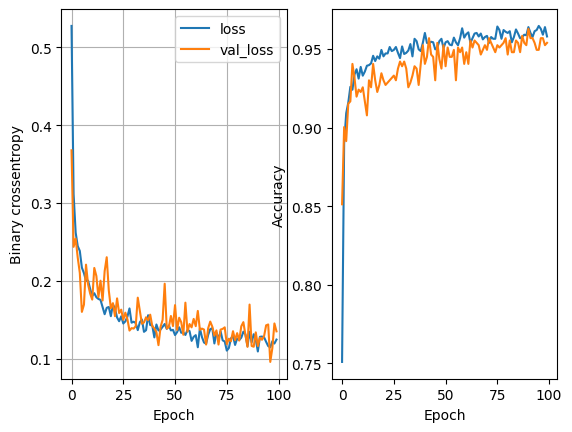

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9191 - loss: 0.3454
16 nodes, dropout 0.4, lr0.005, batch_size16


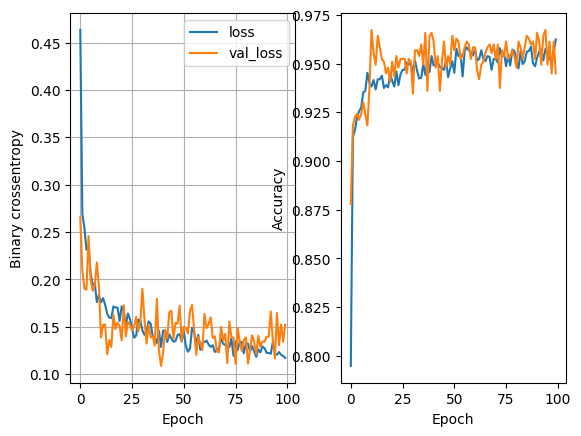

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9236 - loss: 0.3937
16 nodes, dropout 0.4, lr0.005, batch_size32


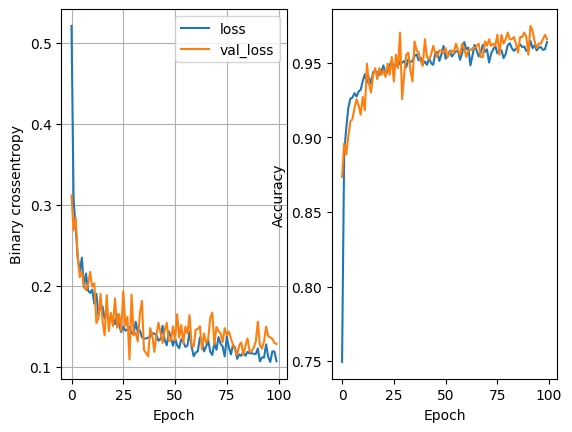

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9188 - loss: 0.4826
16 nodes, dropout 0.4, lr0.005, batch_size64


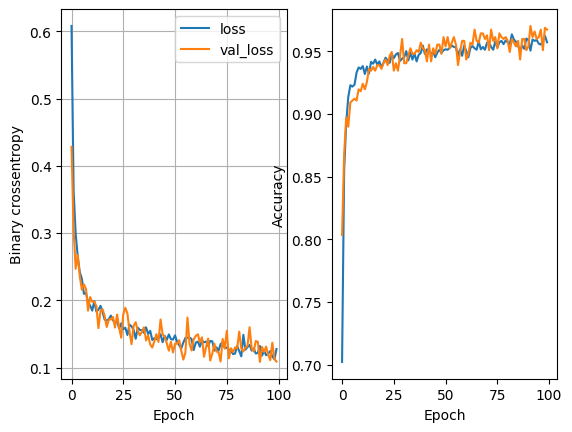

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9331 - loss: 0.3032
16 nodes, dropout 0.4, lr0.001, batch_size16


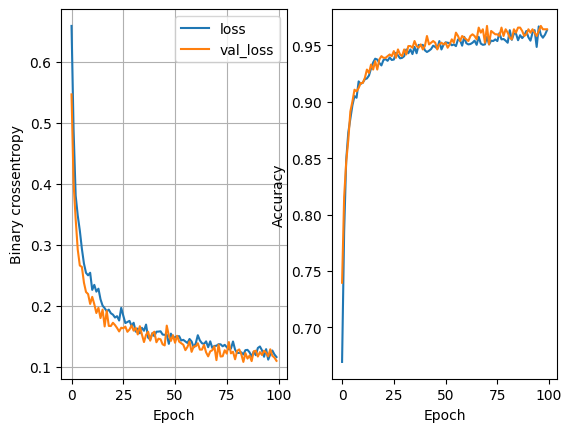

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9368 - loss: 0.2454
16 nodes, dropout 0.4, lr0.001, batch_size32


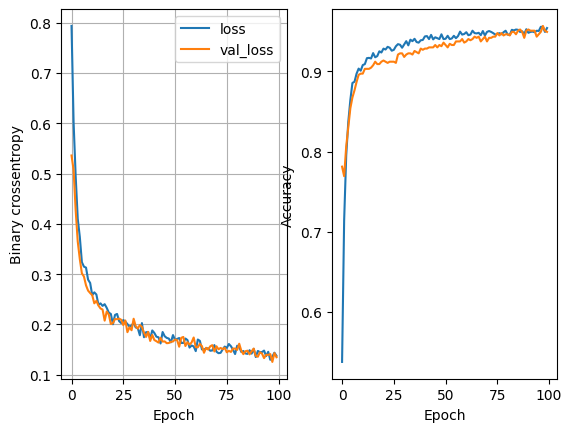

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9271 - loss: 0.2146
16 nodes, dropout 0.4, lr0.001, batch_size64


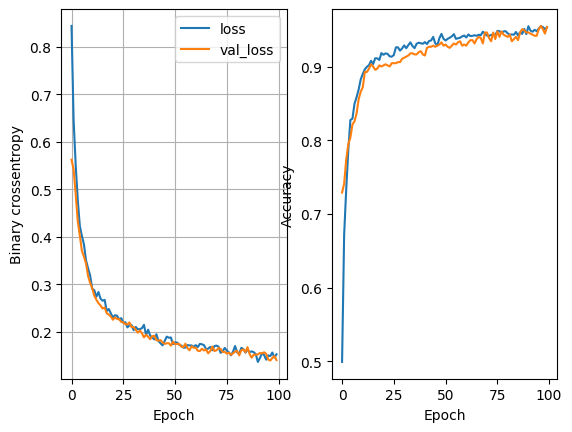

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9273 - loss: 0.2191
32 nodes, dropout 0, lr0.01, batch_size16


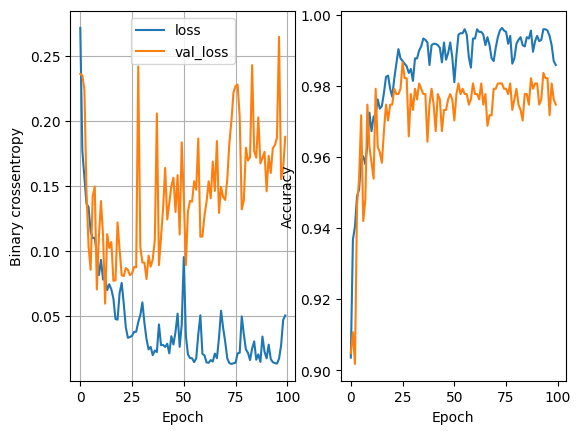

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9175 - loss: 1.2707
32 nodes, dropout 0, lr0.01, batch_size32


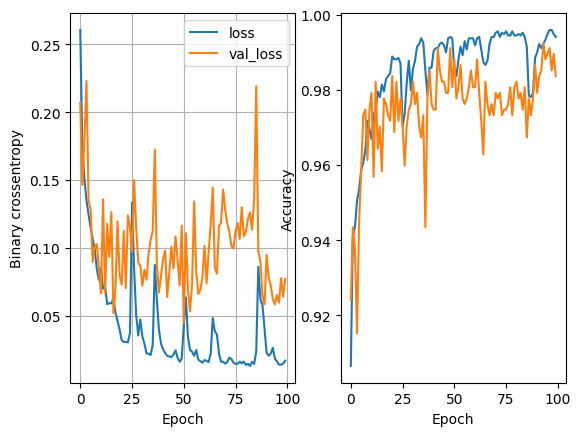

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9207 - loss: 0.7175
32 nodes, dropout 0, lr0.01, batch_size64


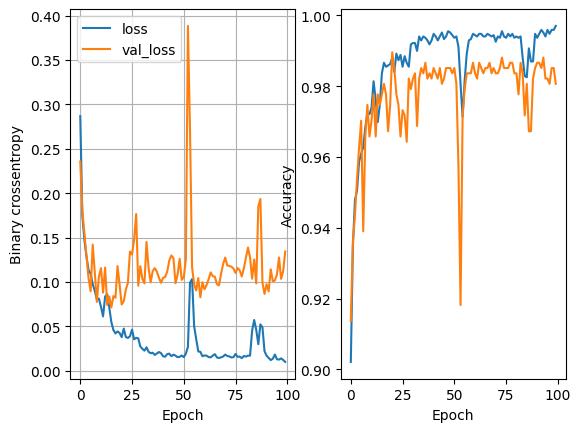

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9279 - loss: 0.7475
32 nodes, dropout 0, lr0.005, batch_size16


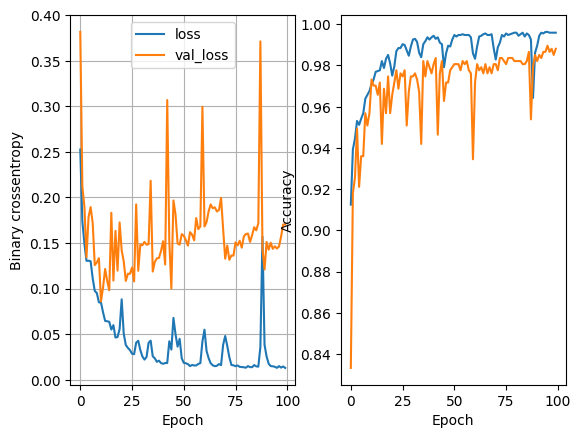

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9310 - loss: 0.9471
32 nodes, dropout 0, lr0.005, batch_size32


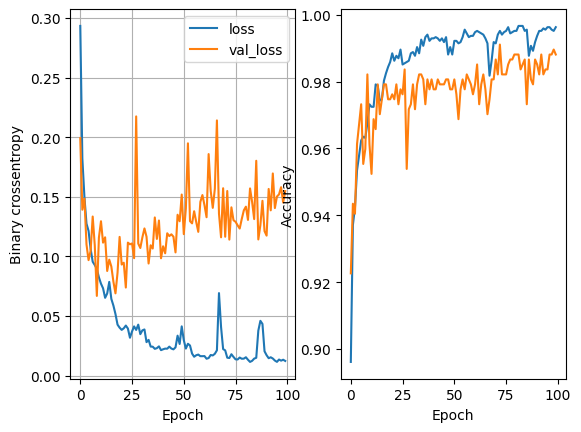

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9371 - loss: 0.9212
32 nodes, dropout 0, lr0.005, batch_size64


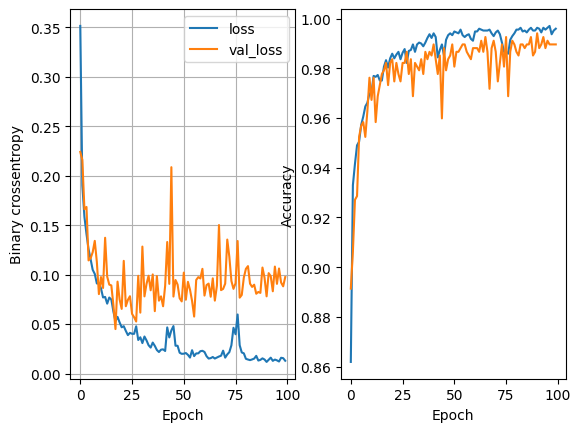

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9388 - loss: 0.6574
32 nodes, dropout 0, lr0.001, batch_size16


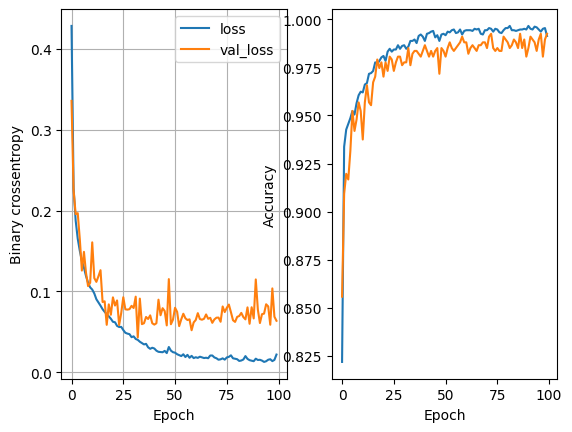

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9458 - loss: 0.5748
32 nodes, dropout 0, lr0.001, batch_size32


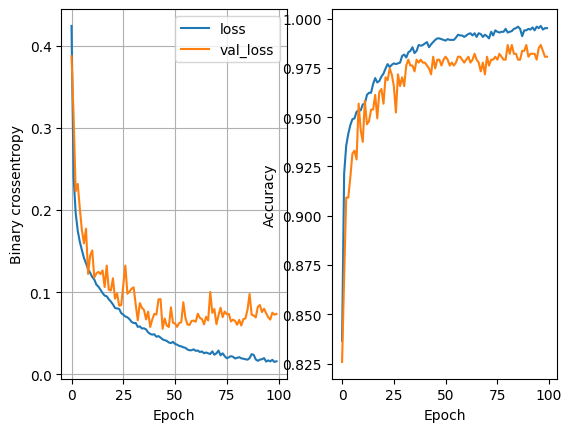

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9126 - loss: 0.7886
32 nodes, dropout 0, lr0.001, batch_size64


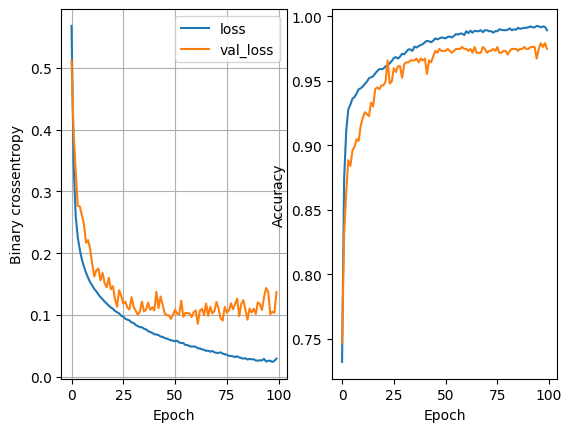

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9216 - loss: 0.4758
32 nodes, dropout 0.2, lr0.01, batch_size16


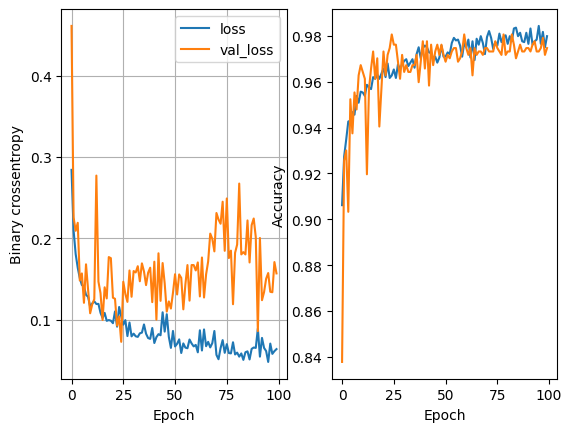

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9194 - loss: 0.7735
32 nodes, dropout 0.2, lr0.01, batch_size32


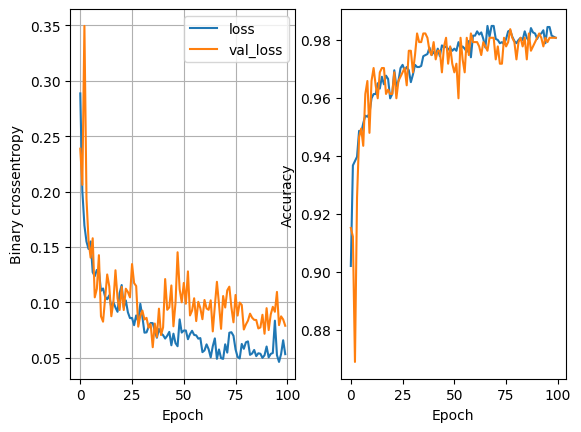

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9331 - loss: 0.5379
32 nodes, dropout 0.2, lr0.01, batch_size64


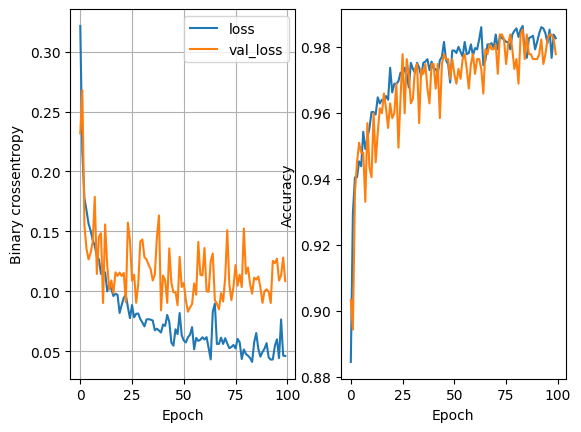

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9267 - loss: 0.7015
32 nodes, dropout 0.2, lr0.005, batch_size16


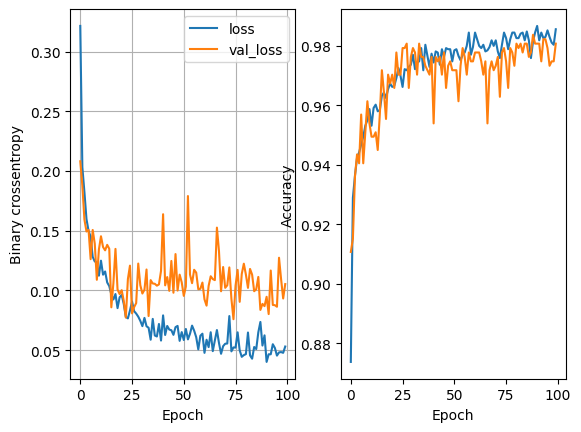

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9287 - loss: 0.5682
32 nodes, dropout 0.2, lr0.005, batch_size32


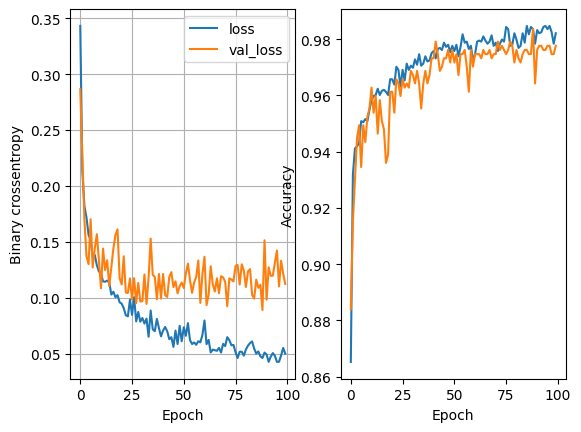

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9271 - loss: 0.5589
32 nodes, dropout 0.2, lr0.005, batch_size64


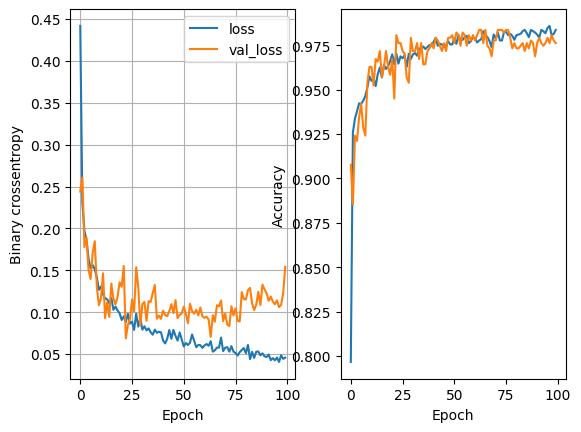

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9208 - loss: 0.6027
32 nodes, dropout 0.2, lr0.001, batch_size16


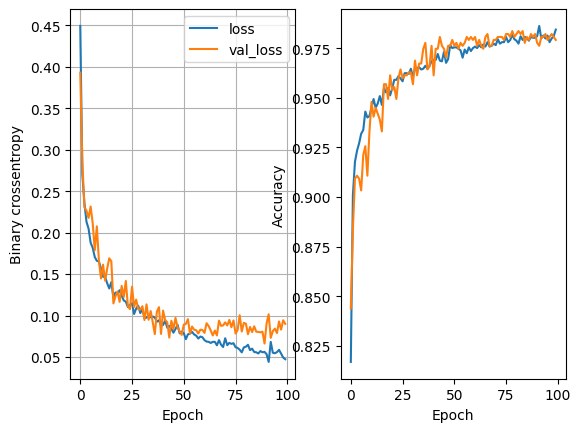

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9436 - loss: 0.3570
32 nodes, dropout 0.2, lr0.001, batch_size32


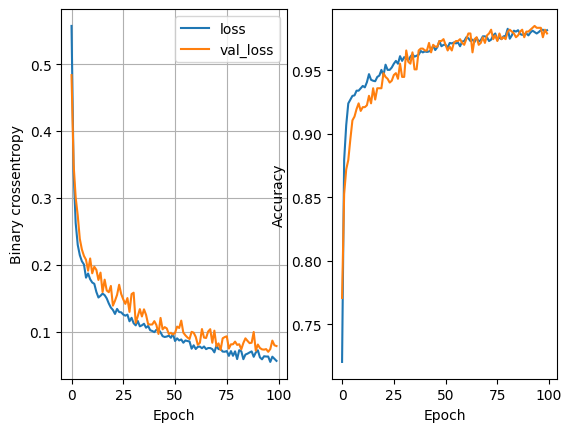

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9300 - loss: 0.3048
32 nodes, dropout 0.2, lr0.001, batch_size64


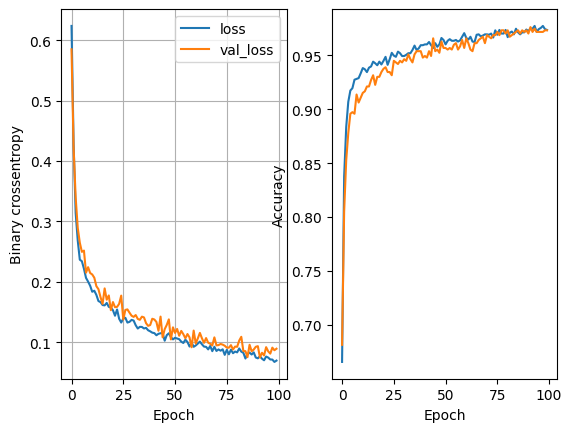

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9248 - loss: 0.3003
32 nodes, dropout 0.4, lr0.01, batch_size16


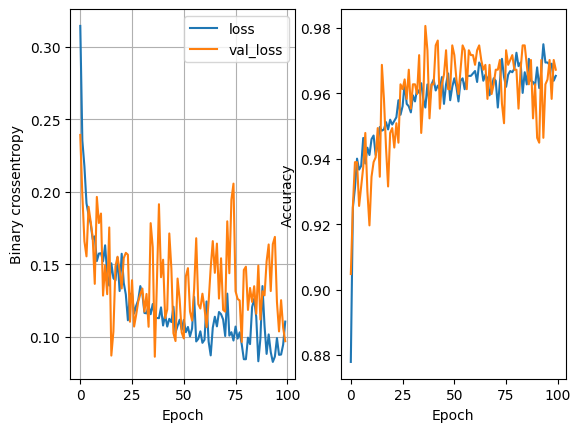

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9231 - loss: 0.5858
32 nodes, dropout 0.4, lr0.01, batch_size32


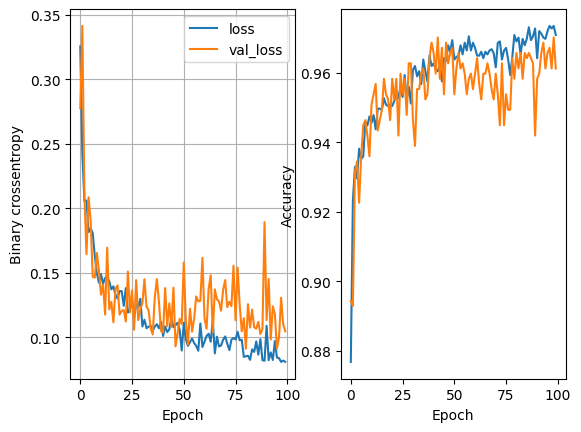

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9259 - loss: 0.4043
32 nodes, dropout 0.4, lr0.01, batch_size64


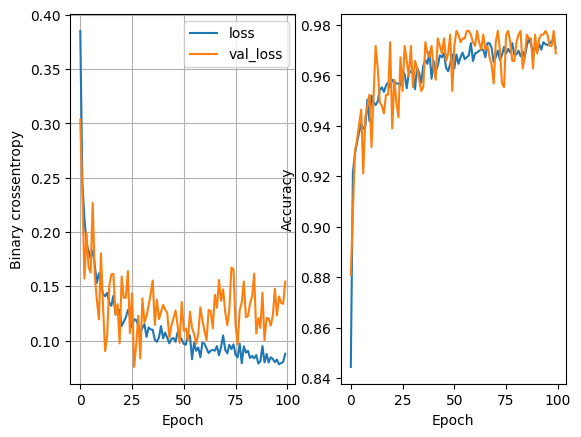

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9294 - loss: 0.4499
32 nodes, dropout 0.4, lr0.005, batch_size16


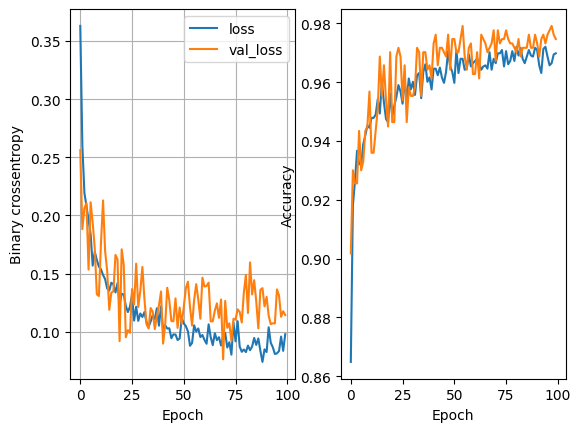

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9253 - loss: 0.4694
32 nodes, dropout 0.4, lr0.005, batch_size32


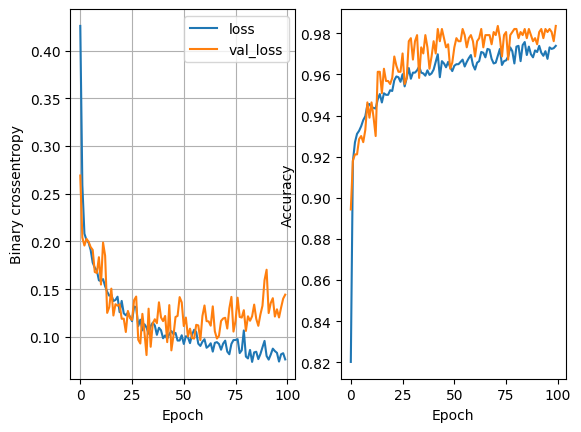

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9167 - loss: 0.5101
32 nodes, dropout 0.4, lr0.005, batch_size64


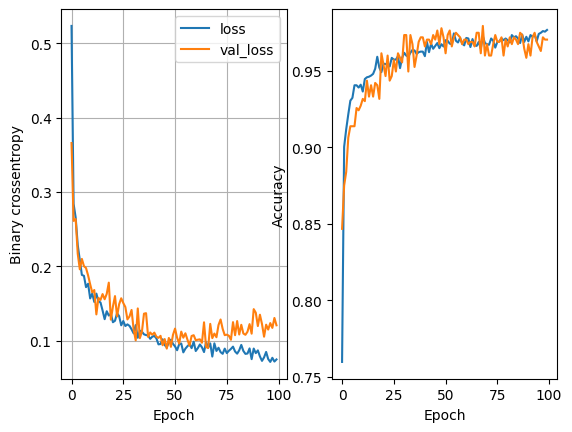

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9233 - loss: 0.4135
32 nodes, dropout 0.4, lr0.001, batch_size16


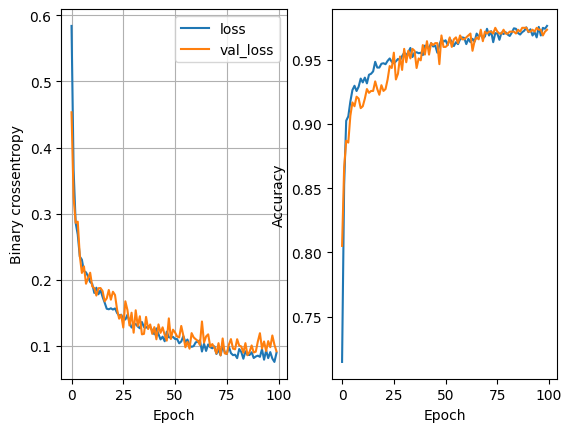

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9313 - loss: 0.2824
32 nodes, dropout 0.4, lr0.001, batch_size32


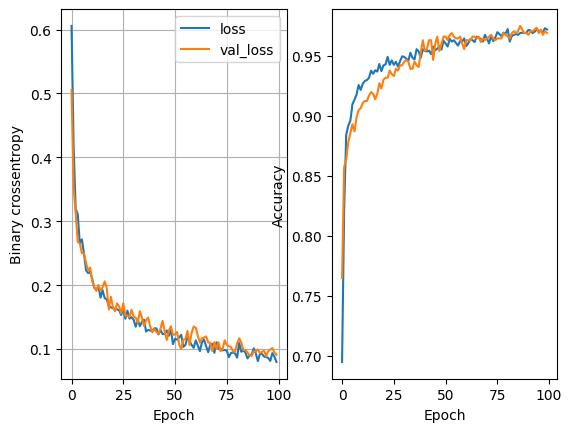

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9242 - loss: 0.2883
32 nodes, dropout 0.4, lr0.001, batch_size64


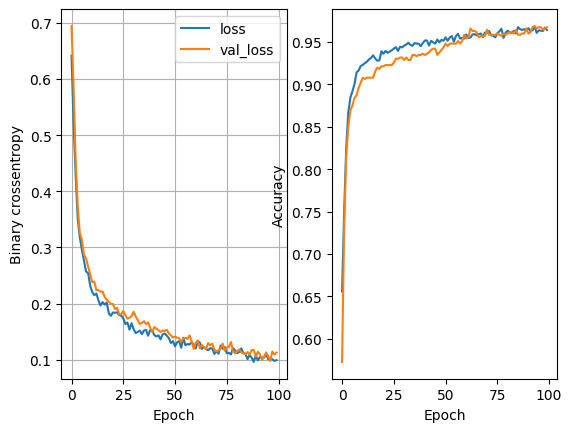

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9290 - loss: 0.2535
64 nodes, dropout 0, lr0.01, batch_size16


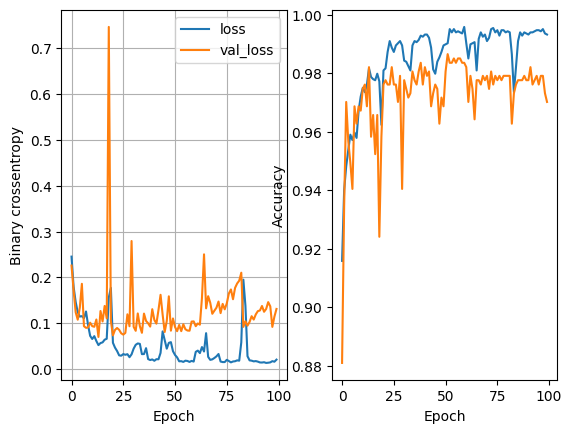

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9288 - loss: 1.1740
64 nodes, dropout 0, lr0.01, batch_size32


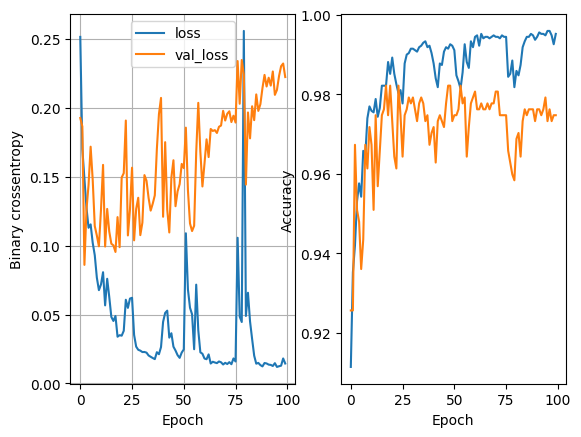

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9313 - loss: 1.2585
64 nodes, dropout 0, lr0.01, batch_size64


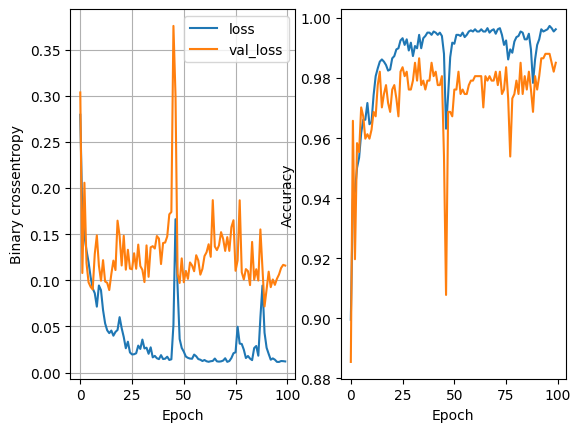

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9204 - loss: 1.1769
64 nodes, dropout 0, lr0.005, batch_size16


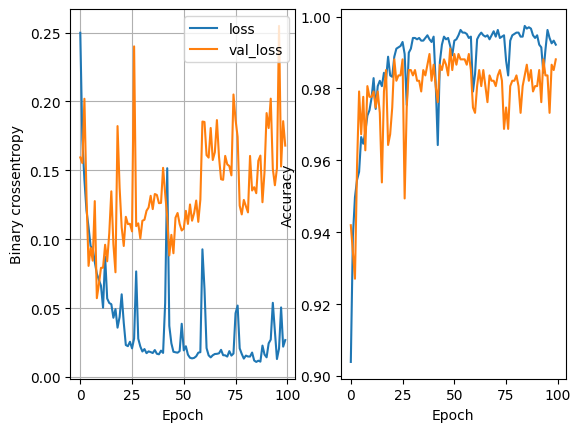

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9265 - loss: 0.9178
64 nodes, dropout 0, lr0.005, batch_size32


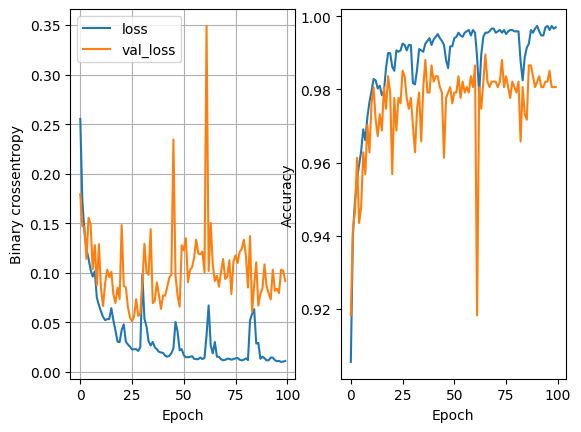

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9312 - loss: 0.8899
64 nodes, dropout 0, lr0.005, batch_size64


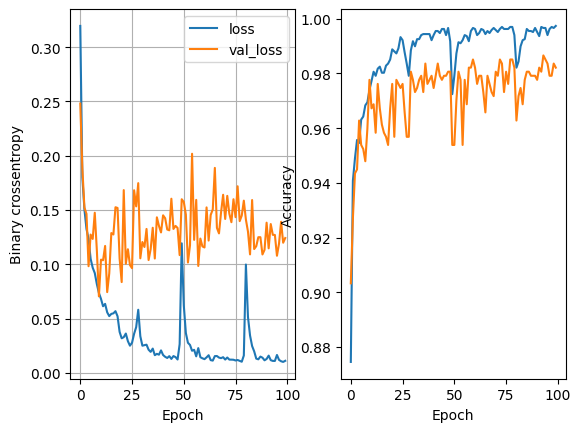

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9281 - loss: 0.7159
64 nodes, dropout 0, lr0.001, batch_size16


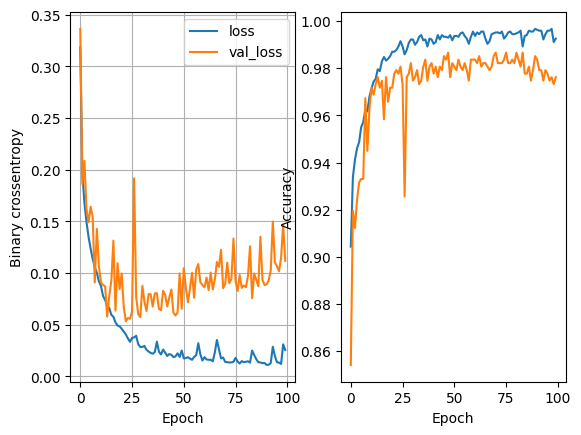

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9300 - loss: 0.5547
64 nodes, dropout 0, lr0.001, batch_size32


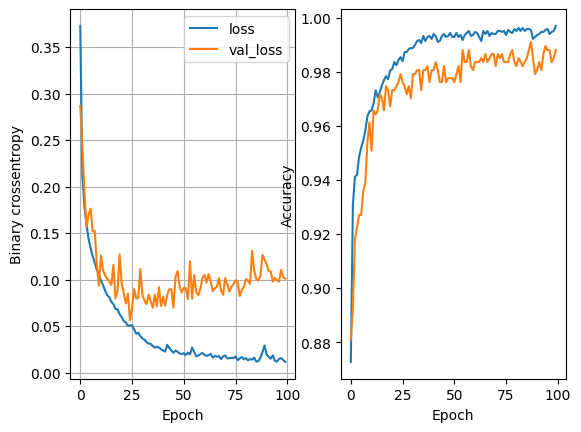

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9285 - loss: 0.6937
64 nodes, dropout 0, lr0.001, batch_size64


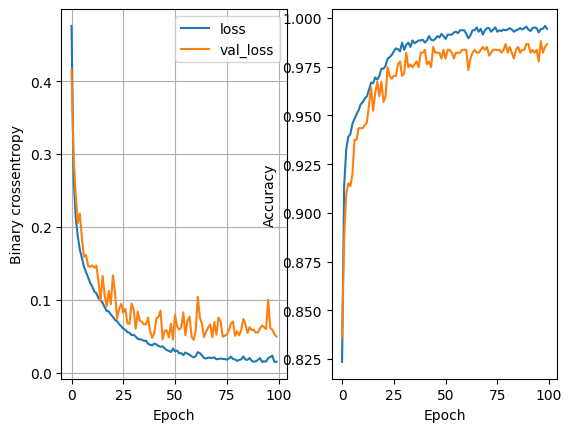

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9244 - loss: 0.5570
64 nodes, dropout 0.2, lr0.01, batch_size16


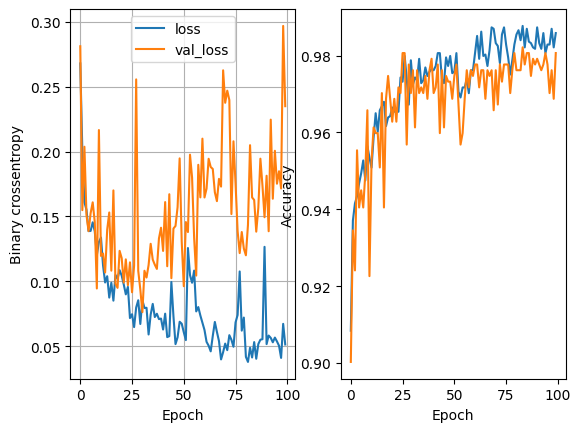

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9337 - loss: 1.5536
64 nodes, dropout 0.2, lr0.01, batch_size32


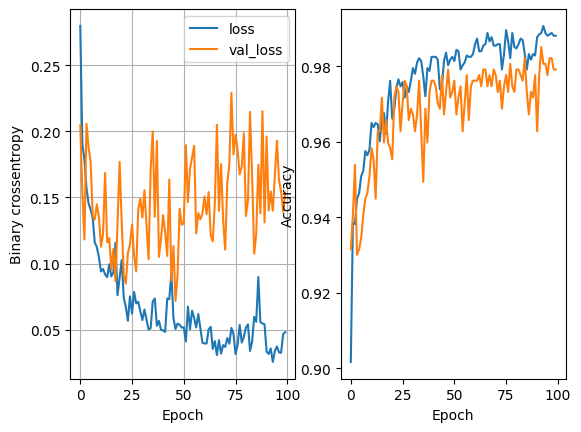

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9270 - loss: 0.5937
64 nodes, dropout 0.2, lr0.01, batch_size64


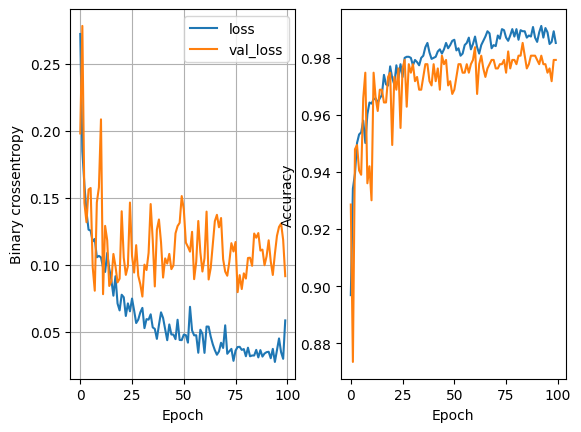

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9344 - loss: 0.6055
64 nodes, dropout 0.2, lr0.005, batch_size16


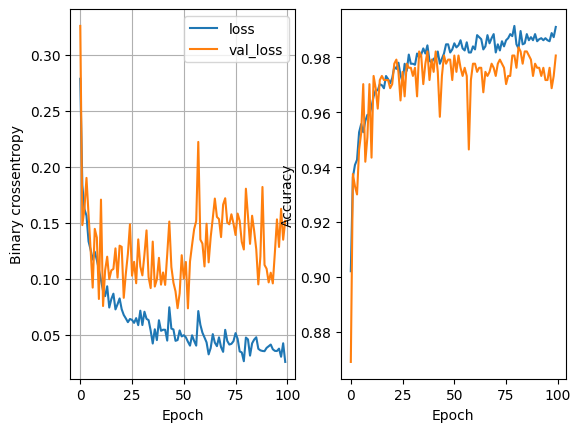

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9337 - loss: 0.8048
64 nodes, dropout 0.2, lr0.005, batch_size32


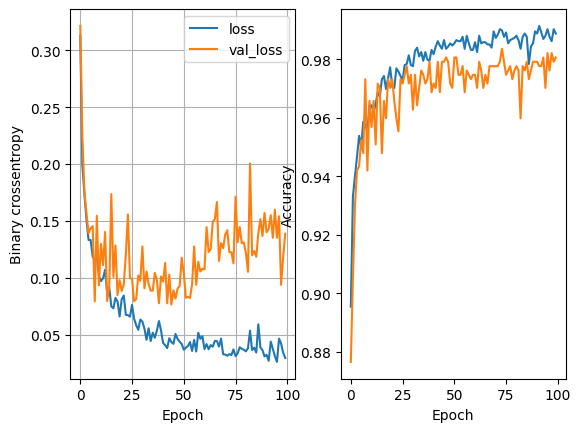

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9400 - loss: 0.7680
64 nodes, dropout 0.2, lr0.005, batch_size64


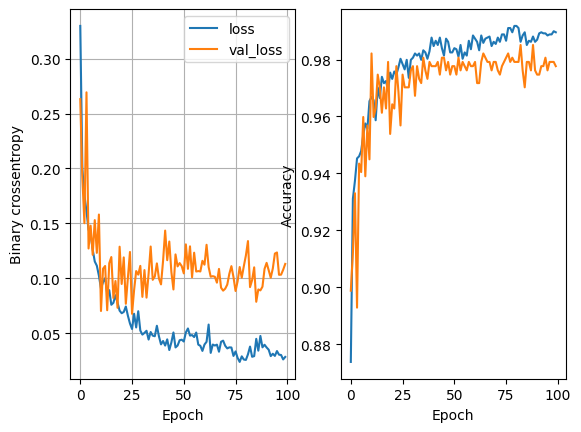

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9355 - loss: 0.5626
64 nodes, dropout 0.2, lr0.001, batch_size16


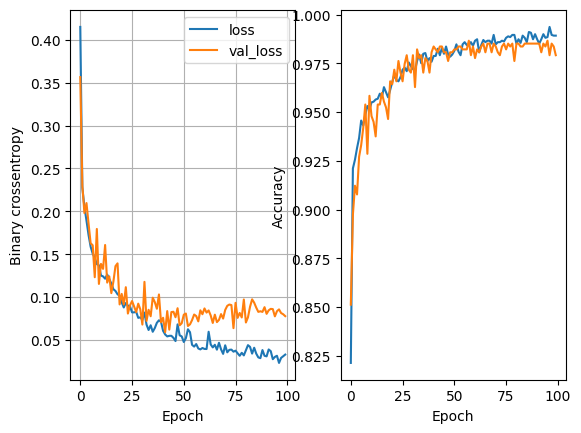

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9398 - loss: 0.4995
64 nodes, dropout 0.2, lr0.001, batch_size32


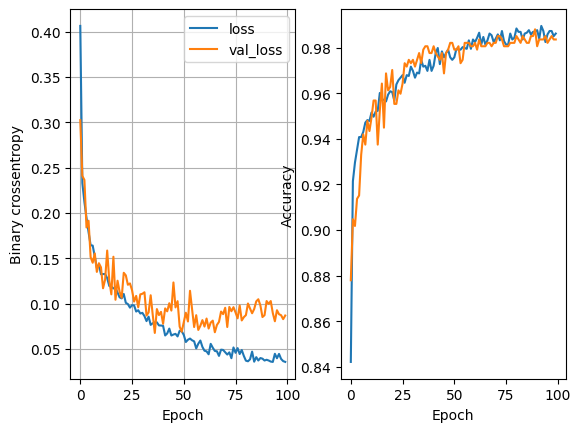

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9422 - loss: 0.4147
64 nodes, dropout 0.2, lr0.001, batch_size64


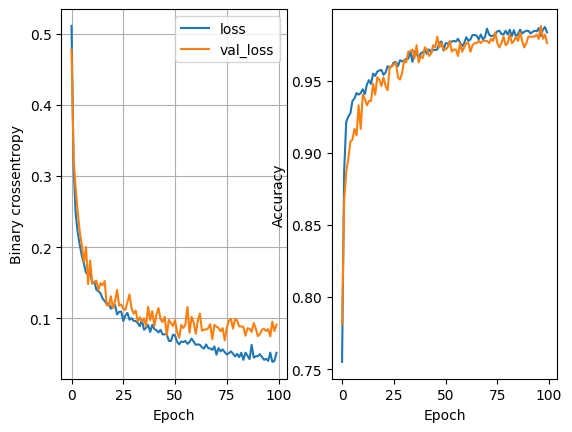

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9292 - loss: 0.3654
64 nodes, dropout 0.4, lr0.01, batch_size16


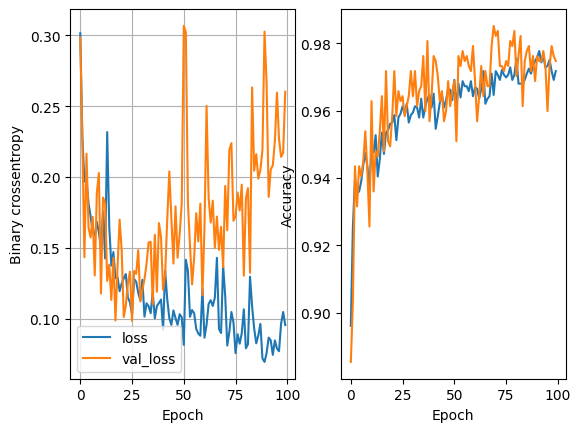

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9248 - loss: 0.9317
64 nodes, dropout 0.4, lr0.01, batch_size32


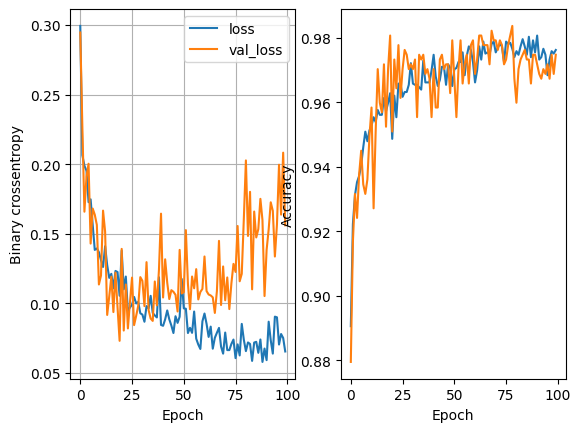

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9351 - loss: 0.8295
64 nodes, dropout 0.4, lr0.01, batch_size64


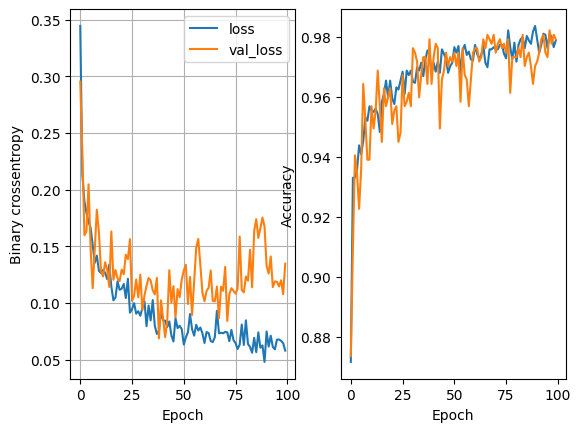

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9229 - loss: 0.5443
64 nodes, dropout 0.4, lr0.005, batch_size16


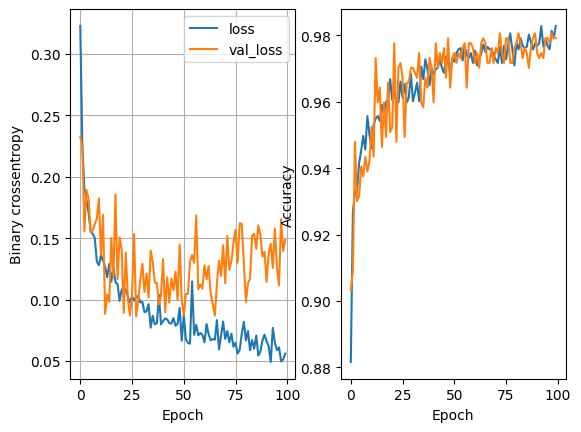

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9255 - loss: 0.8148
64 nodes, dropout 0.4, lr0.005, batch_size32


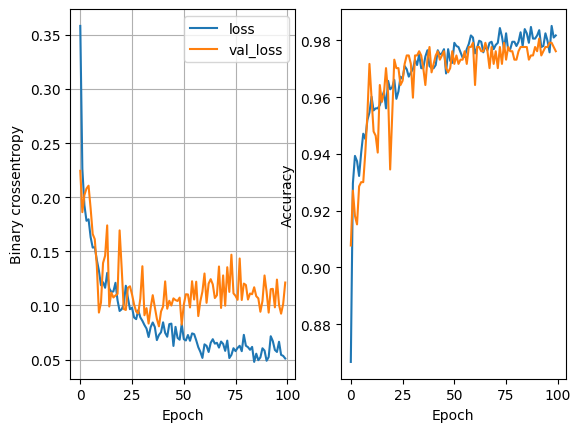

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9222 - loss: 0.5100
64 nodes, dropout 0.4, lr0.005, batch_size64


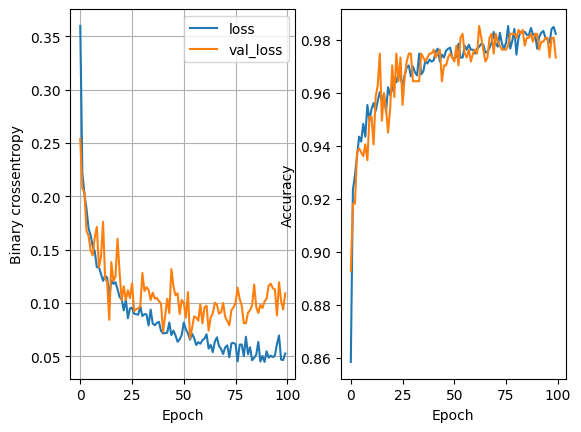

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9294 - loss: 0.4792
64 nodes, dropout 0.4, lr0.001, batch_size16


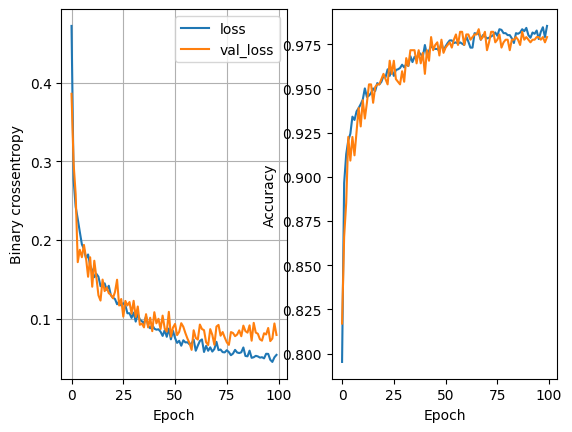

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9401 - loss: 0.4183
64 nodes, dropout 0.4, lr0.001, batch_size32


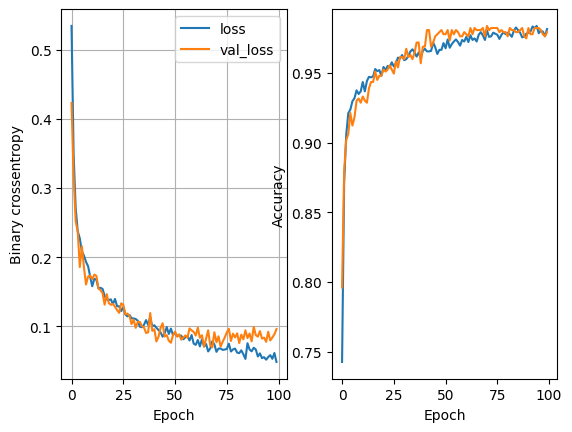

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9352 - loss: 0.3780
64 nodes, dropout 0.4, lr0.001, batch_size64


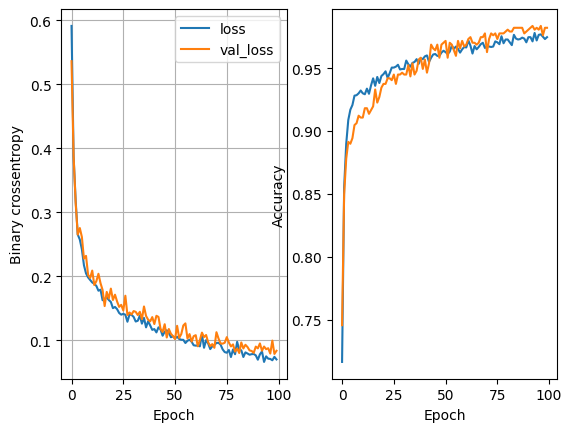

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9297 - loss: 0.2827


In [ ]:
least_val_loss = float('inf') # records whatever model has the leats validation loss- this looks at any model
least_loss_model = None
epochs=100
for num_nodes in [16,32,64]:
  for dropout_prob in [0,0.2, 0.4]:
    for lr in [0.01,0.005,0.001]:
      for batch_size in [16,32,64]:
        print(f"{num_nodes} nodes, dropout {dropout_prob}, lr{lr}, batch_size{batch_size}")
        model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
        plot_history(history)
        val_loss = model.evaluate(X_valid, y_valid)[0] #this wil check the loss in the validation data- ONLY TAKES FIRST ELEMENT [0]
        if val_loss < least_val_loss:
          least_val_loss = val_loss
          least_loss_model = model


In [ ]:
y_pred = least_loss_model.predict(X_test)
y_pred = (y_pred>0.5).astype(int).reshape(-1,)


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       564
           1       0.92      0.91      0.92       357

    accuracy                           0.94       921
   macro avg       0.93      0.93      0.93       921
weighted avg       0.94      0.94      0.94       921

